# MLP para triagem de gravidade de acidentes (PRF, 2007–2026)

Trabalho Prático de Deep Learning (IFG) · Frente 3.1 MLP · Classificação multiclasse
Autor: Igor Coutinho Ferreira Nobre · Repositório GitHub: <https://github.com/coutinhonobre/Trabalho-Final---Pos-Deep-Learning>
Fonte: PRF, "Acidentes nas Rodovias Federais", Portal Brasileiro de Dados Abertos — <https://dados.gov.br/dados/conjuntos-dados/acidentes-rodovias-federais>

**Problema**
- Unidade de observação: 1 acidente (1 linha de `datatranAAAA.csv`), 20 arquivos, 2,24 M linhas.
- Alvo `classificacao_acidente`: `Sem Vítimas` / `Com Vítimas Feridas` / `Com Vítimas Fatais`.
- Uso: priorizar despacho (guincho vs. ambulância) a partir do que a central sabe no 1º contato.

**Entradas (12, todas categóricas → one-hot)**
- Contexto da via: `condicao_metereologica`, `tipo_pista`, `tracado_via`, `fase_dia`.
- Quando/onde: `uf`, `br`, `fim_de_semana` (sex–dom), `periodo_dia` (4 faixas de 6 h).
- Relato do solicitante: `tipo_acidente`, `macro_causa` (7 grupos), `veiculos_cat`, `pessoas_cat`.

**Excluídas**
- `mortos`, `feridos`, `feridos_leves`, `feridos_graves`, `ilesos`, `ignorados`: contam as vítimas e definem o rótulo (vazamento).
- `ano`: a proporção de `Sem Vítimas` cai de ~60% (2007–2014) para ~16% (2019+), uma mudança no procedimento de registro; o modelo aprenderia o registro, não a gravidade.
- `causa_acidente` bruta: vocabulário muda por período (11–12 valores por ano até 2016; de 24 em 2017 até 75 em 2023). Substituída por `macro_causa`.
- `latitude`, `longitude`, `regional`, `delegacia`, `uop`: só existem a partir de 2017 (marcariam o período).
- `sentido_via`: só o sentido da quilometragem. `uso_solo`: fora desta versão (trabalho futuro).
- `km`, `municipio`: cardinalidade alta.

**Stack**: PyTorch (MLP e laço de treino), scikit-learn (encoder, métricas), Optuna (busca de hiperparâmetros).

In [1]:
import os, re, time, json, pickle, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import optuna

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f"torch {torch.__version__} | optuna {optuna.__version__} | pandas {pd.__version__}")

torch 2.14.1 | optuna 5.0.0 | pandas 3.0.6


In [ ]:
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cpu")                     # MLP pequena com one-hot: CPU é mais rápida que GPU
torch.set_num_threads(max(1, os.cpu_count() - 2))

DATA_DIR = Path("datasets")
ARTIFACTS_DIR = Path("artifacts"); ARTIFACTS_DIR.mkdir(exist_ok=True)
FIG_DIR = ARTIFACTS_DIR / "figuras"; FIG_DIR.mkdir(exist_ok=True)

CLASSES = ["Sem Vítimas", "Com Vítimas Feridas", "Com Vítimas Fatais"]
CLASS_COLORS = {"Sem Vítimas": "#2a78d6", "Com Vítimas Feridas": "#eb6834", "Com Vítimas Fatais": "#1baf7a"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.3})

def save_fig(name):                               # salva a figura atual em PNG (para o relatório)
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Dados
### 1.1 Carga
- 20 arquivos, `sep=";"`, `latin-1`, só as colunas necessárias. Concatenação + embaralhamento (semente 42).

In [3]:
TARGET = "classificacao_acidente"
CONTEXTO = ["condicao_metereologica", "tipo_pista", "tracado_via", "fase_dia"]
QUANDO_ONDE = ["uf", "br", "fim_de_semana", "periodo_dia"]
DINAMICA = ["tipo_acidente", "macro_causa", "veiculos_cat", "pessoas_cat"]
FEATURES = CONTEXTO + QUANDO_ONDE + DINAMICA
RAW_COLS = ["id", "mortos", "feridos", "pessoas", "veiculos", "horario", "dia_semana", "uf", "br", "tipo_acidente", "causa_acidente"]

In [4]:
def load_datatran(path, ano):
    df = pd.read_csv(path, sep=";", encoding="latin-1", low_memory=False, usecols=RAW_COLS + CONTEXTO + [TARGET])
    df["fonte"] = ano
    return df

arquivos = sorted(DATA_DIR.glob("datatran*.csv"))
raw = pd.concat([load_datatran(f, int(f.stem[-4:])) for f in arquivos], ignore_index=True)
raw = raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)   # embaralha os anos
print(f"{len(arquivos)} arquivos | {raw.shape[0]:,} linhas x {raw.shape[1]} colunas | {raw.memory_usage(deep=True).sum()/1e9:.1f} GB")
raw.head()

20 arquivos | 2,237,189 linhas x 17 colunas | 1.6 GB


,id,dia_semana,horario,uf,br,causa_acidente,tipo_acidente,classificacao_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,pessoas,mortos,feridos,veiculos,fonte
0,508160.0,sexta-feira,08:10:00,SP,116,Manobra de mudança de faixa,Colisão lateral mesmo sentido,Com Vítimas Feridas,Pleno dia,Céu Claro,Dupla,Curva,3,0,2,2,2023
1,96220.0,quarta-feira,17:05:00,SC,101,Desobediência às normas de trânsito pelo condutor,Tombamento,Com Vítimas Feridas,Pleno dia,Nublado,Simples,Reta,2,0,1,1,2017
2,284057.0,segunda-feira,23:30:00,MS,262,Falta de Atenção à Condução,Saída de leito carroçável,Com Vítimas Feridas,Plena Noite,Nublado,Simples,Aclive;Reta,2,0,1,2,2020
3,1010567.0,Quinta,20:15:00,PR,376,Outras,Atropelamento de animal,Sem Vítimas,Plena noite,Ceu Claro,Simples,Reta,1,0,0,1,2011
4,83311578.0,Domingo,06:40:00,RN,304,Ingestão de álcool,Colisão frontal,Com Vítimas Feridas,Pleno dia,Ceu Claro,Simples,Reta,2,0,1,2,2015


In [5]:
raw.groupby("fonte").size().rename("acidentes").to_frame().T

fonte,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
acidentes,127675,141043,158646,183469,192326,184568,186748,169201,122161,96363,89567,69333,67558,63585,64567,64606,67766,73156,72529,42322


### 1.2 Harmonização
- Normalização de texto (sem acentos/caixa); `Ignorada`→`ignorado`; `(null)`→NaN.
- `tracado_via` multi-rótulo (2017+) → geometria principal: cruzamento > curva > reta > outros.
- Sinônimos de `tipo_acidente` entre formatos unificados (8 regras); causa → 7 macro-causas ("outras"/nulo → `nao informada`).
- Derivadas: `fim_de_semana`, `periodo_dia`, `veiculos_cat` (1–4+), `pessoas_cat` (1–5+). `id` ignorado (numeração reinicia entre anos).

In [6]:
NULL_TOKENS = {"(null)", "null", "na", "nan", "", "none"}

def normalize_text(s):
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", s).strip().lower()

def harmonize_tracado(s):
    if pd.isna(s):
        return np.nan
    joined = " ".join(t.strip() for t in s.split(";"))
    if any(k in joined for k in ["intersecao", "cruzamento", "rotatoria", "retorno"]):
        return "cruzamento"
    if "curva" in joined:
        return "curva"
    if "reta" in joined:
        return "reta"
    return "outros"

normalize_text("Céu Claro"), harmonize_tracado(normalize_text("Aclive;Reta"))   # no pipeline o texto é normalizado antes

('ceu claro', 'reta')

In [7]:
TIPO_SINONIMOS = {"saida de leito carrocavel": "saida de pista", "atropelamento de pedestre": "atropelamento de pessoa",
                  "colisao com objeto estatico": "colisao com objeto fixo", "colisao com objeto": "colisao com objeto fixo",
                  "colisao com objeto em movimento": "colisao com objeto movel", "colisao lateral mesmo sentido": "colisao lateral",
                  "colisao lateral sentido oposto": "colisao lateral", "sinistro pessoal de transito": "eventos atipicos"}

MACRO_CAUSAS = [   # precedência de cima para baixo
    ("pedestre",                 ["pedestre", "calcada"]),
    ("condutor incapacitado",    ["dormindo", "alcool", "psicoativ", "mal subito", "transtornos", "suicidio"]),
    ("velocidade/ultrapassagem", ["velocidade", "ultrapassagem", "contramao", "racha"]),
    ("falha do veiculo",         ["mecanic", "pneu", "freio", "carga", "suspensao", "farois", "farol", "modificacao"]),
    ("via/ambiente",             ["animais", "via", "chuva", "agua", "areia", "oleo", "escorregadia", "objeto", "esburacada", "afundamento",
                                  "sinalizacao", "acostamento", "curva", "iluminacao", "neblina", "fenomenos", "fumaca", "declive",
                                  "visibilidade", "faixas de transito", "redutor", "desvio", "contencao", "area urbana", "semaforo com defeito",
                                  "obras", "desnivel", "drenagem"]),
    ("desatencao/manobra",       ["atencao", "distancia", "reacao", "observar", "manobra", "desobediencia", "preferencia", "conversao",
                                  "retorno", "frear", "estacionar", "motocicleta", "semaforo", "acesso irregular", "celular", "faixa"]),
]
def macro_causa(c):
    if pd.isna(c):
        return np.nan
    for grupo, chaves in MACRO_CAUSAS:
        if any(k in c for k in chaves):
            return grupo
    return "nao informada"

macro_causa("ingestao de alcool pelo condutor"), macro_causa("outras")

('condutor incapacitado', 'nao informada')

In [8]:
def clean(df):
    df = df.copy()
    for c in CONTEXTO + [TARGET]:
        df[c] = df[c].map(normalize_text)
        df.loc[df[c].isin(NULL_TOKENS), c] = np.nan
    df["condicao_metereologica"] = df["condicao_metereologica"].replace({"ignorada": "ignorado"})
    df["tracado_via"] = df["tracado_via"].map(harmonize_tracado)
    # quando e onde
    df["uf"] = df["uf"].map(normalize_text); df.loc[df["uf"].isin(NULL_TOKENS), "uf"] = np.nan; df["uf"] = df["uf"].str.upper()
    df["br"] = pd.to_numeric(df["br"], errors="coerce").astype("Int64").astype(str).replace({"<NA>": np.nan})
    df["hora"] = pd.to_numeric(df["horario"].astype(str).str.slice(0, 2), errors="coerce")
    df["dia_semana"] = df["dia_semana"].map(normalize_text).str.replace("-feira", "", regex=False)
    df["fim_de_semana"] = np.where(df["dia_semana"].isin(["sexta", "sabado", "domingo"]), "sim", "nao")
    df["periodo_dia"] = pd.cut(df["hora"], bins=[-1, 5, 11, 17, 23], labels=["madrugada (0-5h)", "manha (6-11h)", "tarde (12-17h)", "noite (18-23h)"]).astype(str)
    df.loc[df["hora"].isna(), "periodo_dia"] = np.nan
    # relato do solicitante
    df["tipo_acidente"] = df["tipo_acidente"].map(normalize_text).replace(TIPO_SINONIMOS)
    df["causa_acidente"] = df["causa_acidente"].map(normalize_text)
    df["macro_causa"] = df["causa_acidente"].map(macro_causa)
    df["veiculos_cat"] = df["veiculos"].clip(upper=4).astype("Int64").astype(str).replace({"4": "4+"})
    df["pessoas_cat"] = df["pessoas"].clip(upper=5).astype("Int64").astype(str).replace({"5": "5+"})
    df["periodo_registro"] = np.where(df["fonte"] <= 2016, "2007-2016", "2017-2026")   # só para a EDA
    # alvo
    df[TARGET] = df[TARGET].map({"sem vitimas": "Sem Vítimas", "com vitimas feridas": "Com Vítimas Feridas", "com vitimas fatais": "Com Vítimas Fatais"})
    for c in FEATURES + ["dia_semana", "causa_acidente", "periodo_registro"]:
        df[c] = df[c].astype("category")          # economiza memória
    return df

data = clean(raw)
data[FEATURES + [TARGET]].head()

,condicao_metereologica,tipo_pista,tracado_via,fase_dia,uf,br,fim_de_semana,periodo_dia,tipo_acidente,macro_causa,veiculos_cat,pessoas_cat,classificacao_acidente
0,ceu claro,dupla,curva,pleno dia,SP,116,sim,manha (6-11h),colisao lateral,desatencao/manobra,2,3,Com Vítimas Feridas
1,nublado,simples,reta,pleno dia,SC,101,nao,tarde (12-17h),tombamento,desatencao/manobra,1,2,Com Vítimas Feridas
2,nublado,simples,reta,plena noite,MS,262,nao,noite (18-23h),saida de pista,desatencao/manobra,2,2,Com Vítimas Feridas
3,ceu claro,simples,reta,plena noite,PR,376,nao,noite (18-23h),atropelamento de animal,nao informada,1,1,Sem Vítimas
4,ceu claro,simples,reta,pleno dia,RN,304,sim,manha (6-11h),colisao frontal,condutor incapacitado,2,2,Com Vítimas Feridas


In [9]:
for c in FEATURES:                                # 5 categorias mais frequentes de cada entrada
    vc = data[c].value_counts()
    print(f"{c:24s} {vc.size:3d} cats | " + ", ".join(f"{k} ({v/len(data)*100:.0f}%)" for k, v in vc.head(5).items()))

condicao_metereologica    10 cats | ceu claro (52%), nublado (18%), chuva (15%), sol (11%), ignorado (2%)
tipo_pista                 3 cats | simples (52%), dupla (41%), multipla (8%)
tracado_via                4 cats | reta (70%), curva (21%), cruzamento (8%), outros (2%)
fase_dia                   4 cats | pleno dia (57%), plena noite (32%), anoitecer (6%), amanhecer (5%)
uf                        27 cats | MG (14%), SC (11%), PR (10%), RJ (9%), RS (8%)
br                       213 cats | 101 (17%), 116 (17%), 381 (6%), 40 (5%), 153 (4%)
fim_de_semana              2 cats | nao (53%), sim (47%)
periodo_dia                4 cats | tarde (12-17h) (32%), manha (6-11h) (29%), noite (18-23h) (28%), madrugada (0-5h) (11%)
tipo_acidente             19 cats | colisao traseira (25%), colisao lateral (15%), saida de pista (15%), colisao transversal (11%), colisao com objeto fixo (6%)
macro_causa                7 cats | desatencao/manobra (44%), nao informada (20%), velocidade/ultrapassagem (11%

In [10]:
data[TARGET].value_counts(dropna=False)

classificacao_acidente
Com Vítimas Feridas    1076037
Sem Vítimas            1040158
Com Vítimas Fatais      109297
NaN                      11697
Name: count, dtype: int64

## 2. EDA
### 2.1 Descritivas, ausentes, duplicados, anomalias

In [11]:
data[FEATURES + [TARGET]].describe().T

,count,unique,top,freq
condicao_metereologica,2237128,10,ceu claro,1157500
tipo_pista,2237179,3,simples,1154514
tracado_via,2237179,4,reta,1567449
fase_dia,2237119,4,pleno dia,1278730
uf,2237177,27,MG,317124
br,2237177,213,101,384038
fim_de_semana,2237189,2,nao,1182784
periodo_dia,2237189,4,tarde (12-17h),723126
tipo_acidente,2237148,19,colisao traseira,561990
macro_causa,2237189,7,desatencao/manobra,983111


In [12]:
data[["pessoas", "mortos", "feridos", "veiculos"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pessoas,2237189.0,2.27,1.74,1.0,1.0,2.0,3.0,248.0
mortos,2237189.0,0.06,0.30,0.0,0.0,0.0,0.0,37.0
feridos,2237189.0,0.76,1.22,0.0,0.0,1.0,1.0,239.0
veiculos,2237189.0,1.81,0.86,1.0,1.0,2.0,2.0,131.0


In [13]:
missing = pd.DataFrame({"ausentes": data[FEATURES + [TARGET]].isna().sum(),
                        "% do total": (100 * data[FEATURES + [TARGET]].isna().mean()).round(3)})
missing

,ausentes,% do total
condicao_metereologica,61,0.003
tipo_pista,10,0.000
tracado_via,10,0.000
fase_dia,70,0.003
uf,12,0.001
br,12,0.001
fim_de_semana,0,0.000
periodo_dia,0,0.000
tipo_acidente,41,0.002
macro_causa,0,0.000


In [14]:
print("Linhas totalmente idênticas:", raw.duplicated().sum())
print(f"ids repetidos entre arquivos: {raw['id'].duplicated().sum():,} (numeração reiniciada; acidentes diferentes, mantidos)")
print("Linhas idênticas nas 12 entradas + alvo:", data[FEATURES + [TARGET]].duplicated().sum(), "(esperado: contextos repetidos)")

Linhas totalmente idênticas: 6
ids repetidos entre arquivos: 484,076 (numeração reiniciada; acidentes diferentes, mantidos)
Linhas idênticas nas 12 entradas + alvo: 1034180 (esperado: contextos repetidos)


In [15]:
# anomalias: alvo coerente com a contagem de mortos? contagens inválidas? categorias raras?
coer = pd.crosstab(data[TARGET].fillna("<sem rótulo>"), data["mortos"] > 0)
coer.columns = ["mortos == 0", "mortos > 0"]
print("Contagem negativa:", int((data[["pessoas", "mortos", "feridos", "veiculos"]] < 0).any(axis=1).sum()),
      "| pessoas == 0:", int((data["pessoas"] == 0).sum()), "| 10+ veículos:", int((data["veiculos"] >= 10).sum()))
print("Clima (5 mais raros):", data["condicao_metereologica"].value_counts().tail(5).to_dict())
coer

Contagem negativa: 0 | pessoas == 0: 0 | 10+ veículos: 1081
Clima (5 mais raros): {'garoa/chuvisco': 23561, 'nevoeiro/neblina': 22026, 'vento': 5554, 'granizo': 313, 'neve': 117}


,mortos == 0,mortos > 0
classificacao_acidente,,
<sem rótulo>,11694,3
Com Vítimas Fatais,0,109297
Com Vítimas Feridas,1076037,0
Sem Vítimas,1040158,0


- Removidos: alvo fora das 3 classes (`Ignorado`, nulo) e linhas com entrada nula. Perda < 1%.
- Mantidos: `ignorado` no clima (valor legítimo); `neve` (117) e `granizo` (313) são raros: no treino, `neve` fica abaixo de 200 casos e vai para a coluna "infrequente" do encoder, `granizo` mantém coluna própria.

In [16]:
before = len(data)
data = data[data[TARGET].isin(CLASSES)].dropna(subset=FEATURES).reset_index(drop=True)
print(f"Linhas antes: {before:,} | depois: {len(data):,} | removidas: {before - len(data):,} ({100*(before-len(data))/before:.2f}%)")

Linhas antes: 2,237,189 | depois: 2,225,314 | removidas: 11,875 (0.53%)


### 2.2 Alvo

In [17]:
counts = data[TARGET].value_counts().reindex(CLASSES)
print("Rácio de desbalanceamento (maior / menor classe):", round(counts.max() / counts.min(), 1))
counts

Rácio de desbalanceamento (maior / menor classe): 9.8


classificacao_acidente
Sem Vítimas            1040080
Com Vítimas Feridas    1075945
Com Vítimas Fatais      109289
Name: count, dtype: int64

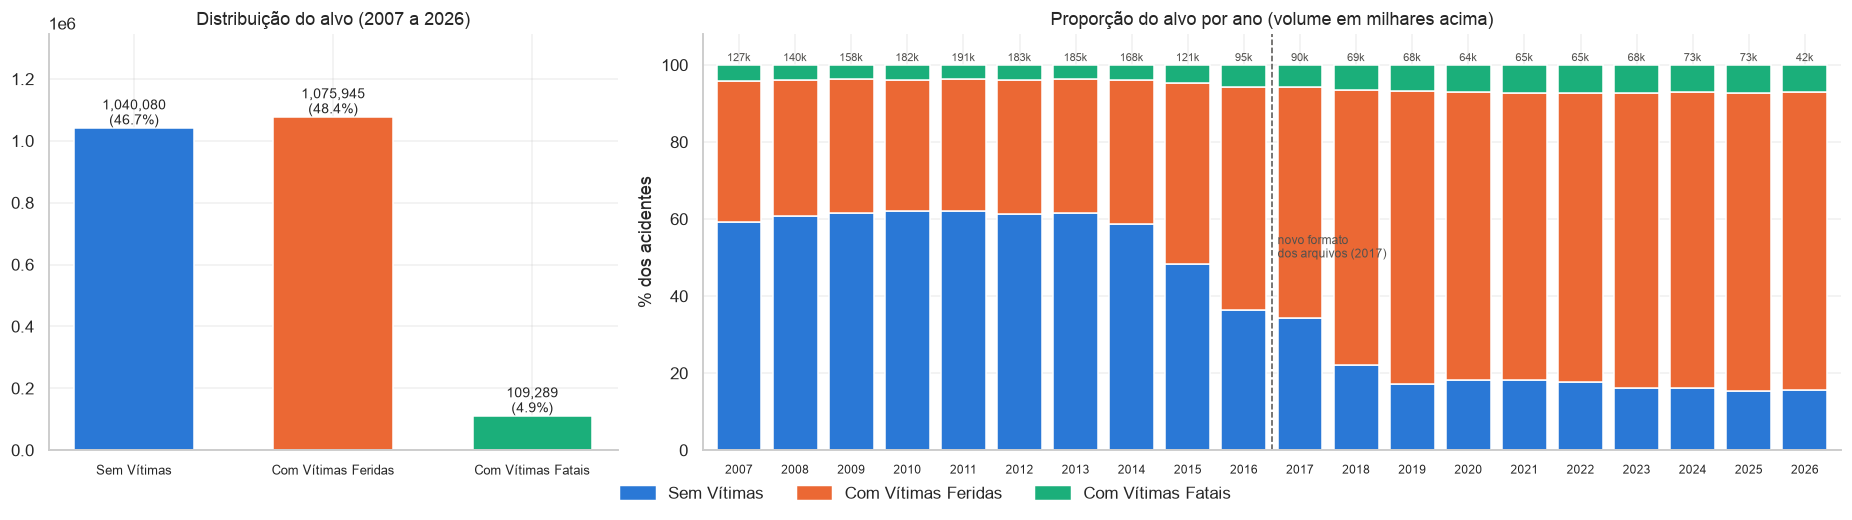

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index], width=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({100*v/counts.sum():.1f}%)", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Distribuição do alvo (2007 a 2026)"); axes[0].set_ylim(0, counts.max() * 1.25); axes[0].tick_params(axis="x", labelsize=8.5)

prop = pd.crosstab(data["fonte"], data[TARGET], normalize="index").reindex(columns=CLASSES) * 100
prop.plot(kind="bar", stacked=True, ax=axes[1], color=[CLASS_COLORS[c] for c in CLASSES], width=0.8, rot=0, legend=False)
for j, (ano, n) in enumerate(data.groupby("fonte").size().items()):
    axes[1].text(j, 101, f"{n/1000:.0f}k", ha="center", fontsize=7, color="#52514e")
axes[1].axvline(9.5, color="#52514e", ls="--", lw=1); axes[1].text(9.6, 50, "novo formato\ndos arquivos (2017)", fontsize=8, color="#52514e")
axes[1].set_title("Proporção do alvo por ano (volume em milhares acima)"); axes[1].set_ylabel("% dos acidentes"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", labelsize=8); axes[1].set_ylim(0, 108)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS[c]) for c in CLASSES], CLASSES, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
save_fig("01_alvo")

- Rácio de desbalanceamento 9,8; fatais = 4,9%.
- `Sem Vítimas`: ~60% de 2007 a 2014, depois 48% (2015), 36% (2016), 34% (2017), 22% (2018) e ~16% de 2019 em diante. Queda rápida demais para ser mudança no perfil dos acidentes: indica mudança no procedimento de registro. Motivo da exclusão de `ano`.

### 2.3 Hora e dia da semana

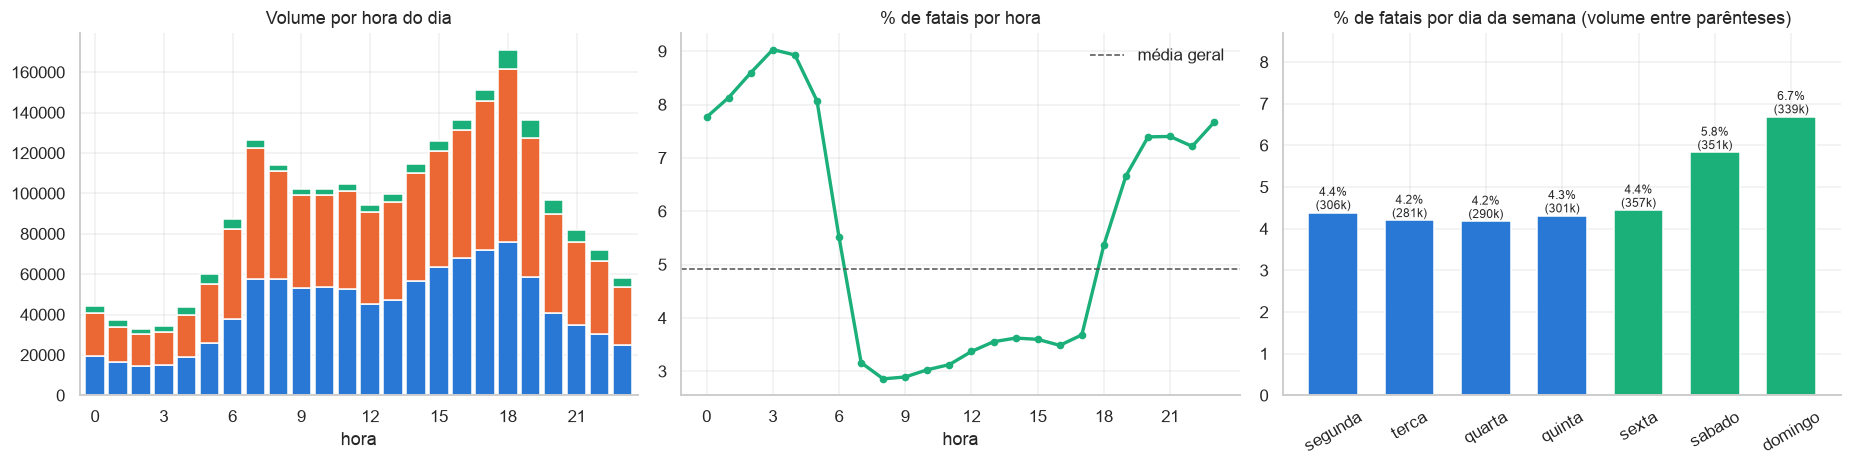

In [19]:
fatal = lambda s: (s == "Com Vítimas Fatais").mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
pd.crosstab(data["hora"], data[TARGET]).reindex(columns=CLASSES).plot(kind="bar", stacked=True, ax=axes[0], color=[CLASS_COLORS[c] for c in CLASSES], width=0.85, legend=False)
axes[0].set_title("Volume por hora do dia"); axes[0].set_xlabel("hora"); axes[0].set_xticks(range(0, 24, 3)); axes[0].set_xticklabels(range(0, 24, 3), rotation=0)

fr = data.groupby("hora")[TARGET].apply(fatal)
axes[1].plot(fr.index, fr.values, color="#1baf7a", lw=2.2, marker="o", ms=4)
axes[1].axhline(fatal(data[TARGET]), color="#52514e", ls="--", lw=1, label="média geral")
axes[1].set_title("% de fatais por hora"); axes[1].set_xlabel("hora"); axes[1].set_xticks(range(0, 24, 3)); axes[1].legend(frameon=False)

order = ["segunda", "terca", "quarta", "quinta", "sexta", "sabado", "domingo"]
wk = data.groupby("dia_semana", observed=True)[TARGET].agg(total="size", fatais=fatal).reindex(order)
axes[2].bar(wk.index, wk["fatais"], color=["#1baf7a" if d in ("sexta", "sabado", "domingo") else "#2a78d6" for d in wk.index], width=0.65)
for i, (d, row) in enumerate(wk.iterrows()):
    axes[2].text(i, row["fatais"] + 0.08, f"{row['fatais']:.1f}%\n({row['total']/1000:.0f}k)", ha="center", fontsize=8)
axes[2].set_title("% de fatais por dia da semana (volume entre parênteses)"); axes[2].set_ylim(0, wk["fatais"].max() * 1.3); axes[2].tick_params(axis="x", rotation=30)
save_fig("02_hora_dia_semana")

- Taxa de fatais: máxima na madrugada e sex–dom; mínima 7–17 h. Origem de `periodo_dia` e `fim_de_semana`.

### 2.4 Distribuição das entradas por regime de registro

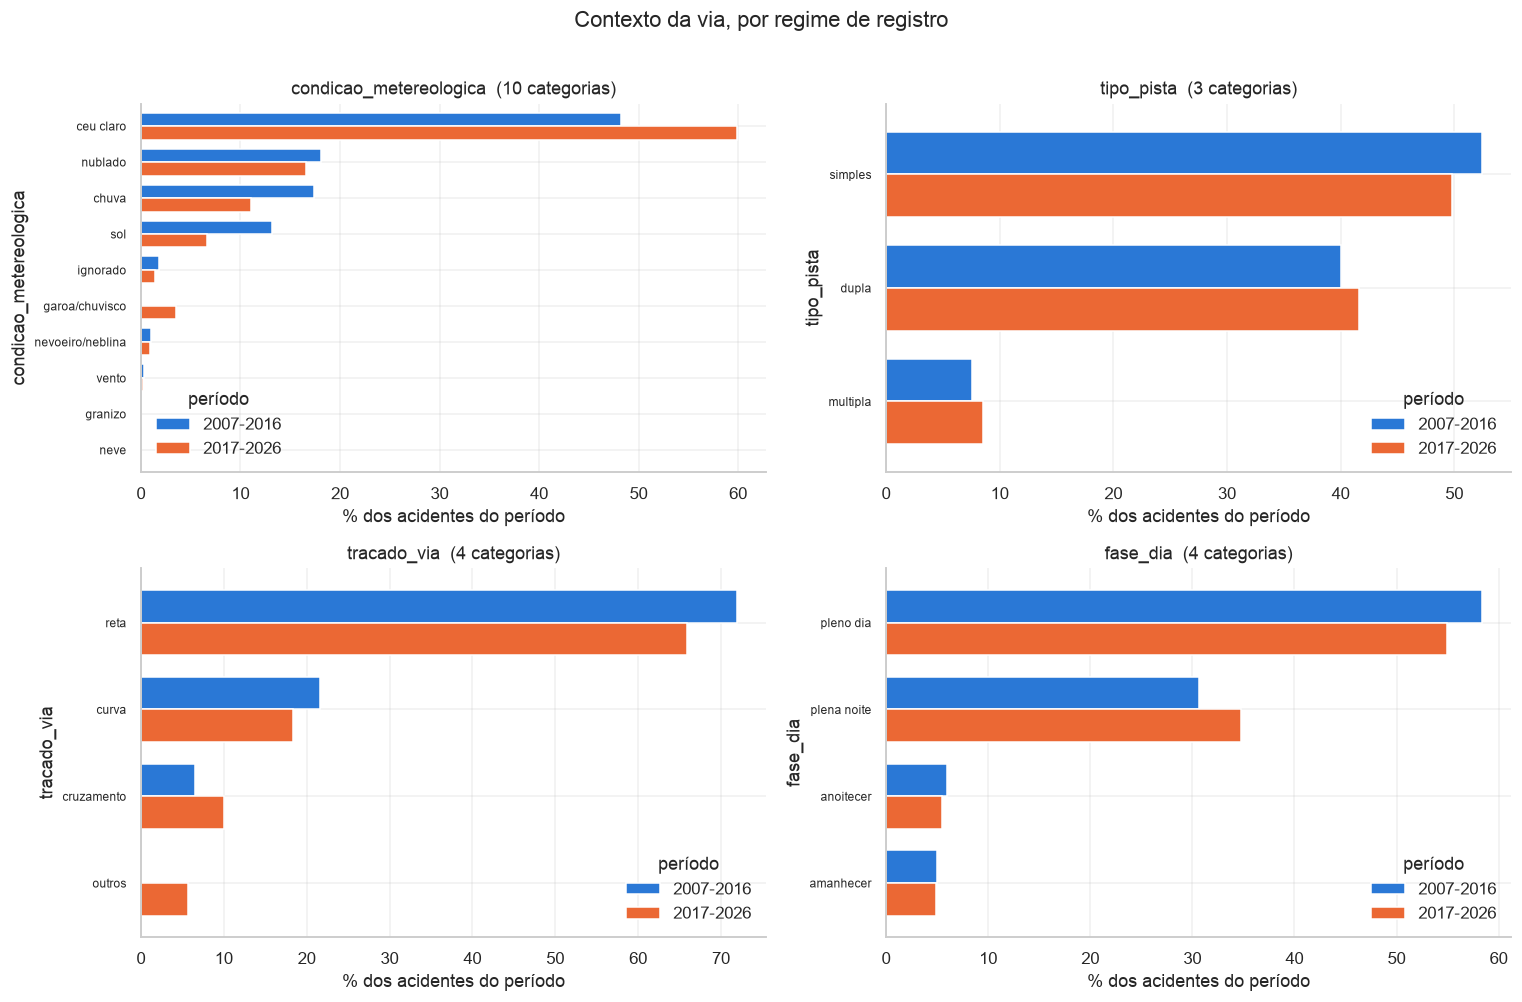

In [20]:
def plot_por_regime(cols, tops, titulo, nome):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, col, top in zip(axes.ravel(), cols, tops):
        ct = pd.crosstab(data[col], data["periodo_registro"])
        ct_pct = (ct.div(ct.sum(0), axis=1) * 100).loc[ct.sum(1).sort_values(ascending=False).index[:top]]
        ct_pct.plot(kind="barh", ax=ax, color=["#2a78d6", "#eb6834"], width=0.75)
        ax.set_title(f"{col}  ({data[col].nunique()} categorias)"); ax.set_xlabel("% dos acidentes do período"); ax.invert_yaxis()
        ax.tick_params(axis="y", labelsize=8); ax.legend(title="período", frameon=False)
    plt.suptitle(titulo, y=1.01); save_fig(nome)

plot_por_regime(CONTEXTO, [10, 3, 4, 4], "Contexto da via, por regime de registro", "03_contexto_por_regime")

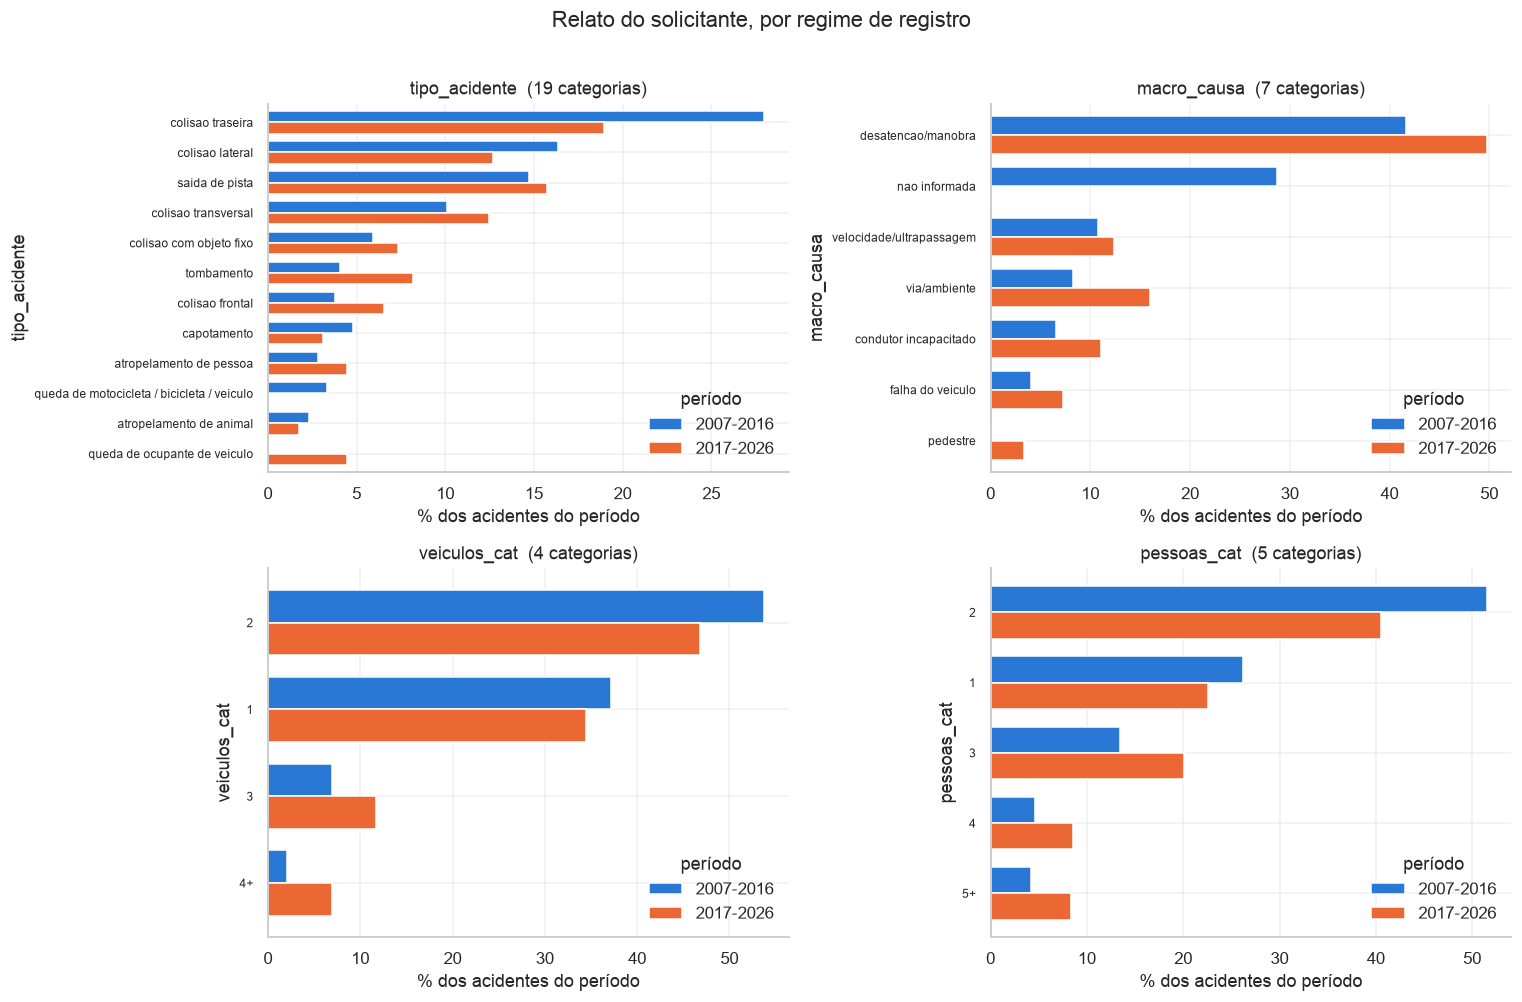

In [21]:
plot_por_regime(DINAMICA, [12, 7, 4, 5], "Relato do solicitante, por regime de registro", "04_relato_por_regime")

- Contexto da via: distribuições estáveis entre regimes.
- Relato: formato 2017+ traz causas detalhadas e `pedestre`; `nao informada` concentra o "outras" pré-2017 (marca o período; limitação).

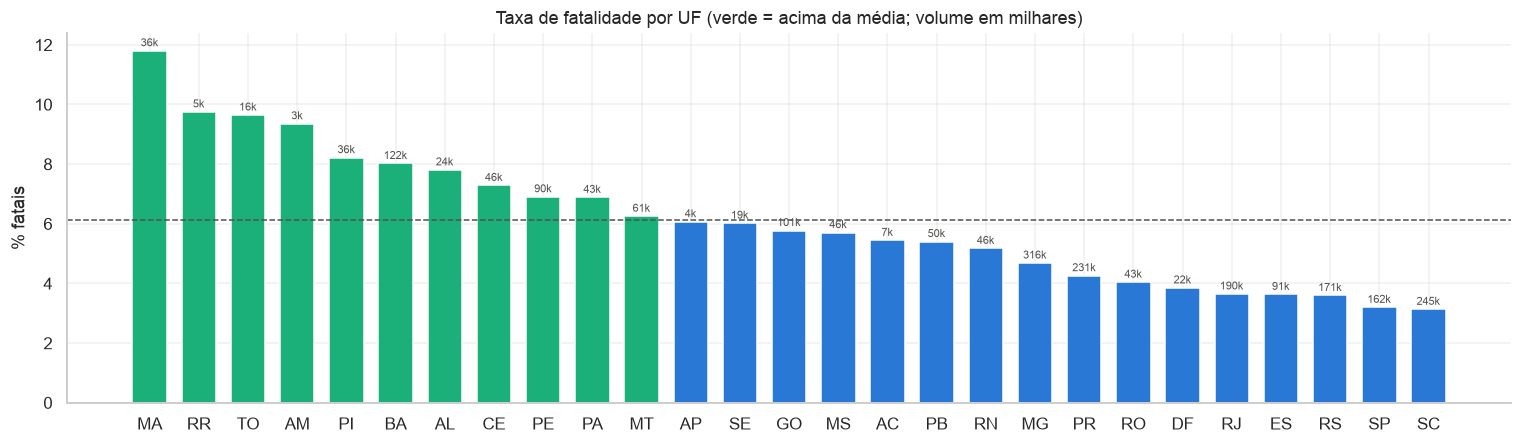

In [22]:
uf_stats = data.groupby("uf", observed=True)[TARGET].agg(total="size", fatais=fatal)
uf_stats = uf_stats[uf_stats["total"] >= 500].sort_values("fatais", ascending=False)
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.bar(uf_stats.index, uf_stats["fatais"], color=["#1baf7a" if v >= uf_stats["fatais"].mean() else "#2a78d6" for v in uf_stats["fatais"]], width=0.7)
ax.axhline(uf_stats["fatais"].mean(), color="#52514e", ls="--", lw=1)
for i, (uf, row) in enumerate(uf_stats.iterrows()):
    ax.text(i, row["fatais"] + 0.15, f"{row['total']/1000:.0f}k", ha="center", fontsize=7.5, color="#52514e")
ax.set_ylabel("% fatais"); ax.set_title("Taxa de fatalidade por UF (verde = acima da média; volume em milhares)")
save_fig("05_uf")

### 2.5 Entradas × alvo

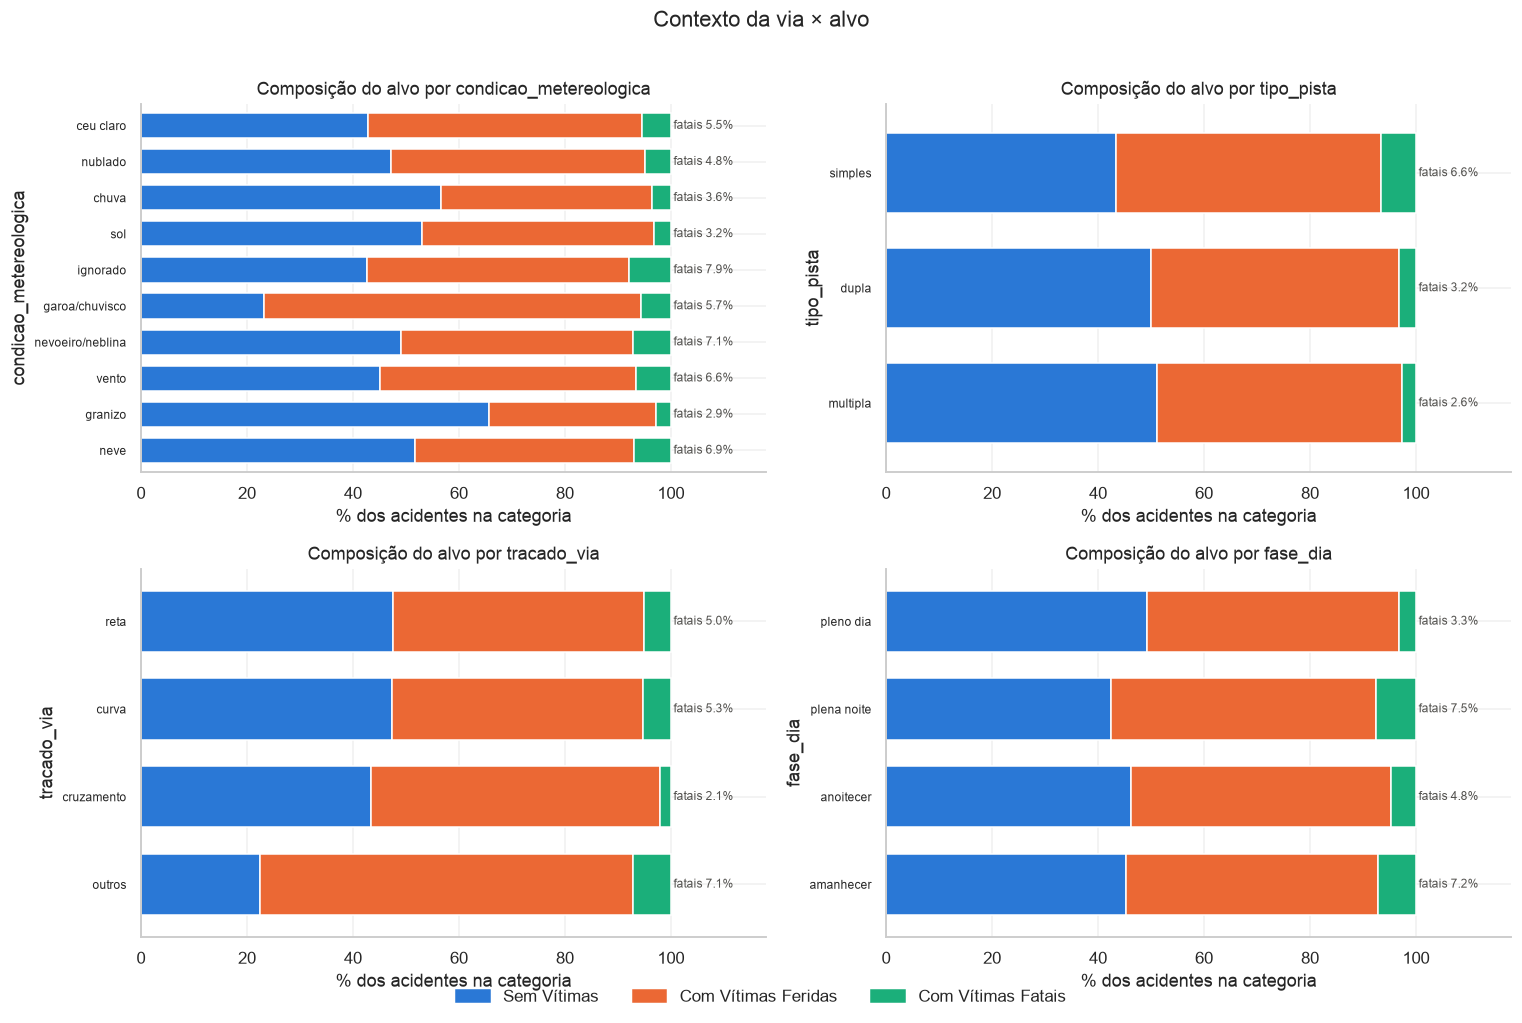

In [23]:
def plot_composicao(cols, tops, titulo, nome):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, col, top in zip(axes.ravel(), cols, tops):
        keep = data[col].value_counts().index[:top]
        ct = pd.crosstab(data[col], data[TARGET], normalize="index").reindex(columns=CLASSES).loc[keep] * 100
        ct.plot(kind="barh", stacked=True, ax=ax, color=[CLASS_COLORS[c] for c in CLASSES], width=0.7, legend=False)
        for i, v in enumerate(ct["Com Vítimas Fatais"].values):
            ax.text(100.5, i, f"fatais {v:.1f}%", va="center", fontsize=8, color="#52514e")
        ax.set_title(f"Composição do alvo por {col}"); ax.set_xlabel("% dos acidentes na categoria"); ax.set_xlim(0, 118)
        ax.invert_yaxis(); ax.tick_params(axis="y", labelsize=8)
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS[c]) for c in CLASSES], CLASSES, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01))
    plt.suptitle(titulo, y=1.01); save_fig(nome)

plot_composicao(CONTEXTO, [10, 3, 4, 4], "Contexto da via × alvo", "06_composicao_contexto")

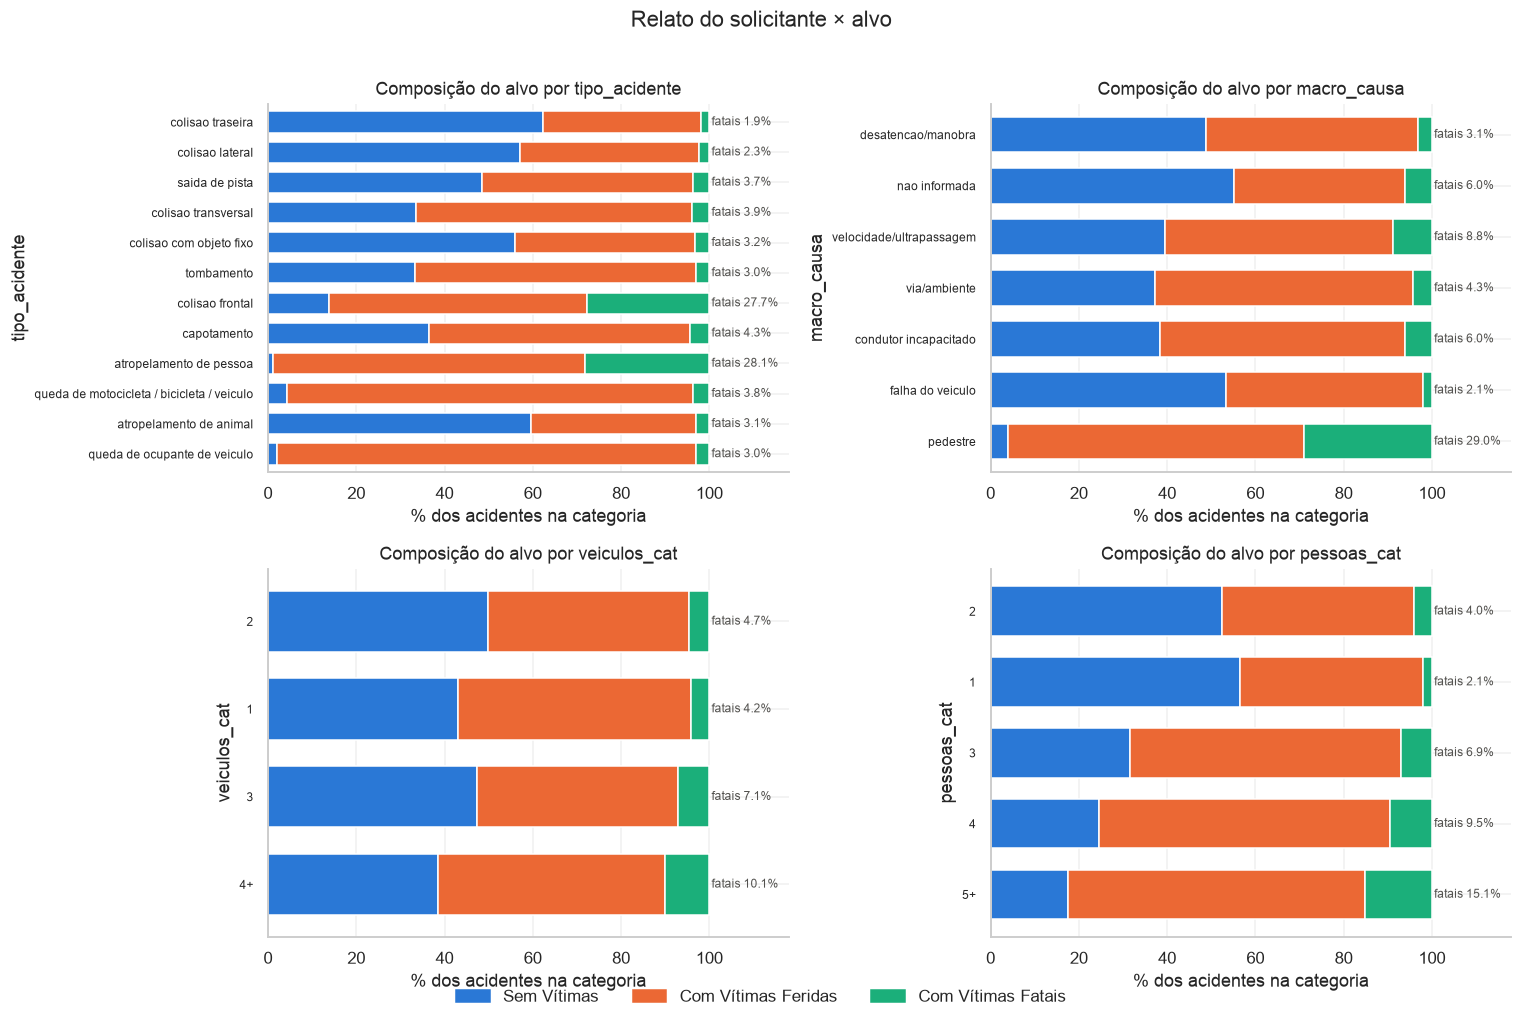

In [24]:
plot_composicao(DINAMICA, [12, 7, 4, 5], "Relato do solicitante × alvo", "07_composicao_relato")

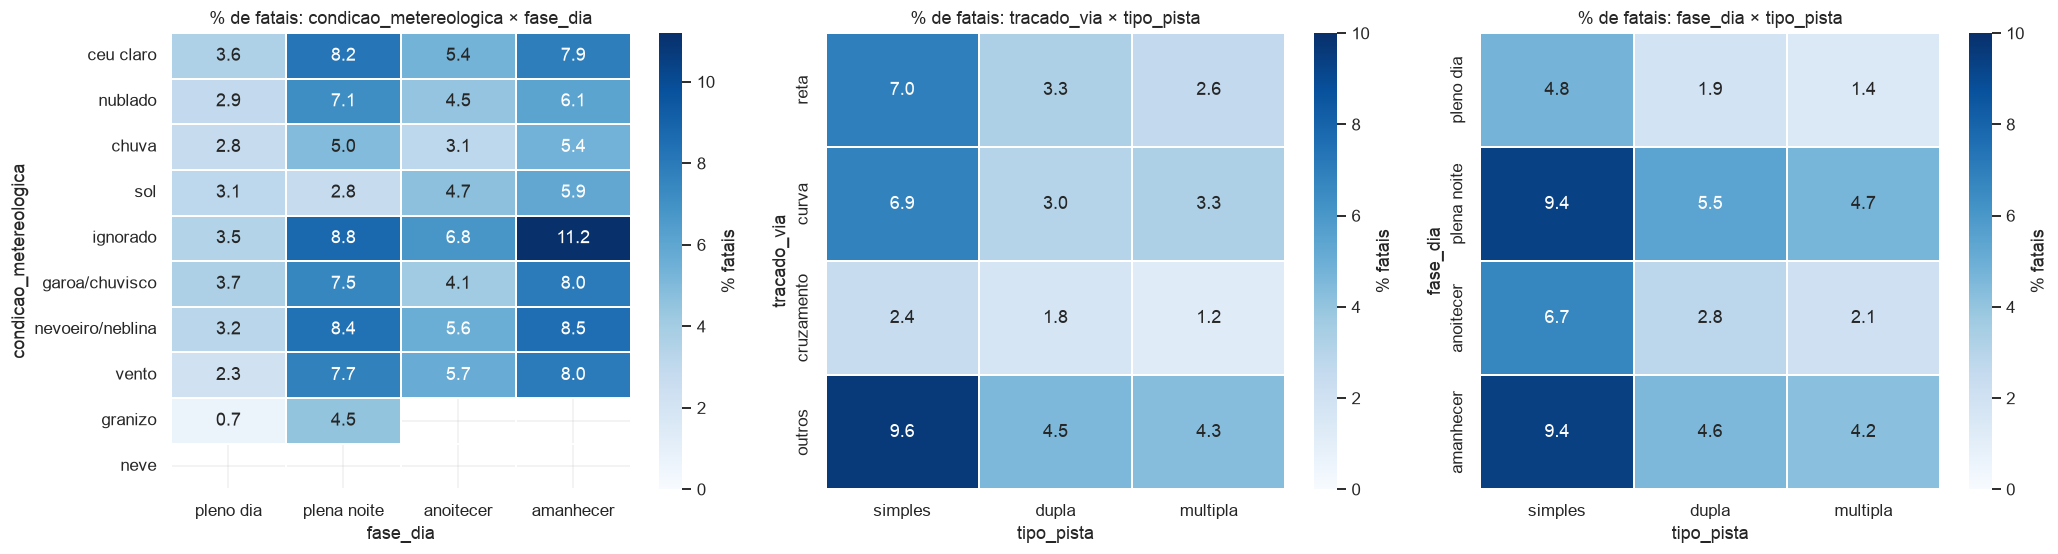

In [25]:
def fatal_heatmap(ax, row, col, min_n=100):
    sub = data.groupby([row, col], observed=True)[TARGET].agg(n="size", fatais=fatal).reset_index()
    sub.loc[sub["n"] < min_n, "fatais"] = np.nan
    piv = sub.pivot(index=row, columns=col, values="fatais")
    piv = piv.loc[data[row].value_counts().index.intersection(piv.index), data[col].value_counts().index.intersection(piv.columns)]
    sns.heatmap(piv, ax=ax, cmap="Blues", annot=True, fmt=".1f", linewidths=1, linecolor="white", cbar_kws={"label": "% fatais"}, vmin=0, vmax=max(10, np.nanmax(piv.values)))
    ax.set_title(f"% de fatais: {row} × {col}"); ax.set_xlabel(col); ax.set_ylabel(row)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
fatal_heatmap(axes[0], "condicao_metereologica", "fase_dia")
fatal_heatmap(axes[1], "tracado_via", "tipo_pista")
fatal_heatmap(axes[2], "fase_dia", "tipo_pista")
save_fig("08_heatmaps_contexto")

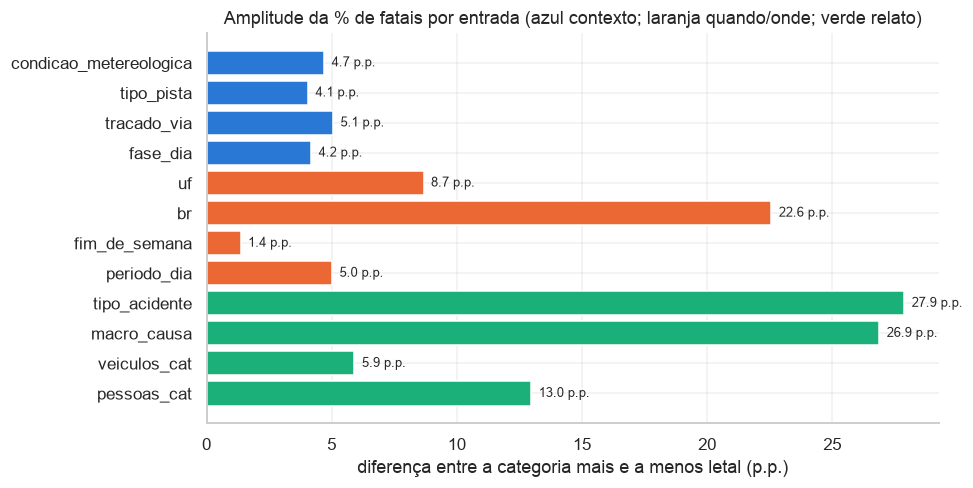

condicao_metereologica     4.7
tipo_pista                 4.1
tracado_via                5.1
fase_dia                   4.2
uf                         8.7
br                        22.6
fim_de_semana              1.4
periodo_dia                5.0
tipo_acidente             27.9
macro_causa               26.9
veiculos_cat               5.9
pessoas_cat               13.0
dtype: float64

In [26]:
def spread(col, min_n=500):                       # amplitude da % de fatais entre categorias
    g = data.groupby(col, observed=True)[TARGET].agg(total="size", fatais=fatal)
    g = g[g["total"] >= min_n]
    return g["fatais"].max() - g["fatais"].min()

sp = pd.Series({c: spread(c) for c in FEATURES})
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(sp.index, sp.values, color=["#2a78d6"] * 4 + ["#eb6834"] * 4 + ["#1baf7a"] * 4)
for i, v in enumerate(sp.values): ax.text(v + 0.3, i, f"{v:.1f} p.p.", va="center", fontsize=8.5)
ax.invert_yaxis(); ax.set_xlabel("diferença entre a categoria mais e a menos letal (p.p.)")
ax.set_title("Amplitude da % de fatais por entrada (azul contexto; laranja quando/onde; verde relato)")
save_fig("09_amplitude_fatais")
sp.round(1)

- Contexto: composição quase constante entre categorias; interações entre 2% e 10% de fatais.
- Relato: atropelamento e colisão frontal ~28% de fatais; tombamento 3%; com 1 pessoa envolvida a taxa de fatais é 2,1% (5,9% com 2 ou mais).
- Amplitude entre categorias: contexto 4,1–5,1 p.p.; `tipo_acidente` 27,9 p.p.; `macro_causa` 26,9 p.p.
- Desbalanceamento tratado com `class_weight` na perda e Macro F1 como métrica de seleção.

## 3. Pré-processamento
### 3.1 Divisão estratificada 70/15/15
- `stratify` no alvo, semente 42, antes de qualquer transformação. O teste só é usado na seção 5.
- 70/15/15: com 2,2 M linhas, 15% = 333 k exemplos (16 mil fatais no teste) já dão estimativas estáveis; o restante vai para o treino.

In [27]:
X = data[FEATURES].copy()
y = data[TARGET].map({c: i for i, c in enumerate(CLASSES)}).astype(int).values
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"treino {len(y_train):,} | validação {len(y_val):,} | teste {len(y_test):,}")

treino 1,557,719 | validação 333,797 | teste 333,798


In [28]:
pd.DataFrame({"treino": pd.Series(y_train).value_counts(normalize=True).sort_index(),
              "validação": pd.Series(y_val).value_counts(normalize=True).sort_index(),
              "teste": pd.Series(y_test).value_counts(normalize=True).sort_index()}).rename(index=dict(enumerate(CLASSES))).mul(100).round(2)

,treino,validação,teste
Sem Vítimas,46.74,46.74,46.74
Com Vítimas Feridas,48.35,48.35,48.35
Com Vítimas Fatais,4.91,4.91,4.91


### 3.2 One-hot (fit só no treino)
- Redes trabalham melhor com entradas numéricas ou binárias; aqui todas são categóricas por natureza (é o que a central sabe), então viram binárias com one-hot.
- `OneHotEncoder(min_frequency=200, handle_unknown="infrequent_if_exist")`: raras e desconhecidas → coluna "infrequente".
- Sem normalização numérica (entradas binárias).

In [29]:
encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200, sparse_output=False, dtype=np.float32)
encoder.fit(X_train)                                  # ajuste SOMENTE no treino
X_train_enc = encoder.transform(X_train)
X_val_enc = encoder.transform(X_val)
X_test_enc = encoder.transform(X_test)
feature_names = encoder.get_feature_names_out(FEATURES)
print("treino", X_train_enc.shape, "| validação", X_val_enc.shape, "| teste", X_test_enc.shape)

treino (1557719, 194) | validação (333797, 194) | teste (333798, 194)


In [30]:
pd.Series({col: len(cats) - (len(inf) - 1 if inf is not None and len(inf) > 0 else 0)
           for col, cats, inf in zip(FEATURES, encoder.categories_, encoder.infrequent_categories_)}, name="colunas one-hot").to_frame().T

,condicao_metereologica,tipo_pista,tracado_via,fase_dia,uf,br,fim_de_semana,periodo_dia,tipo_acidente,macro_causa,veiculos_cat,pessoas_cat
colunas one-hot,10,3,4,4,27,105,2,4,19,7,4,5


In [31]:
X_train.head()

,condicao_metereologica,tipo_pista,tracado_via,fase_dia,uf,br,fim_de_semana,periodo_dia,tipo_acidente,macro_causa,veiculos_cat,pessoas_cat
1987934,sol,simples,outros,pleno dia,RS,471,nao,manha (6-11h),saida de pista,desatencao/manobra,1,1
597961,nublado,simples,curva,plena noite,PR,116,sim,noite (18-23h),queda de motocicleta / bicicleta / veiculo,desatencao/manobra,1,1
2004071,ceu claro,dupla,reta,plena noite,SC,282,sim,noite (18-23h),colisao traseira,desatencao/manobra,2,3
1323826,chuva,dupla,curva,pleno dia,GO,60,nao,tarde (12-17h),saida de pista,via/ambiente,1,1
976639,ceu claro,dupla,reta,pleno dia,GO,40,nao,manha (6-11h),colisao traseira,desatencao/manobra,3,4


In [32]:
pd.DataFrame(X_train_enc[:5], columns=feature_names, index=X_train.index[:5]).astype(int).iloc[:, :14]   # 14 primeiras colunas

,condicao_metereologica_ceu claro,condicao_metereologica_chuva,condicao_metereologica_garoa/chuvisco,condicao_metereologica_granizo,condicao_metereologica_ignorado,condicao_metereologica_nevoeiro/neblina,condicao_metereologica_nublado,condicao_metereologica_sol,condicao_metereologica_vento,condicao_metereologica_infrequent_sklearn,tipo_pista_dupla,tipo_pista_multipla,tipo_pista_simples,tracado_via_cruzamento
1987934,0,0,0,0,0,0,0,1,0,0,0,0,1,0
597961,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2004071,1,0,0,0,0,0,0,0,0,0,1,0,0,0
1323826,0,1,0,0,0,0,0,0,0,0,1,0,0,0
976639,1,0,0,0,0,0,0,0,0,0,1,0,0,0


In [33]:
exemplo = pd.DataFrame([{"condicao_metereologica": "ceu claro", "tipo_pista": "simples", "tracado_via": "reta", "fase_dia": "pleno dia",
                         "uf": "GO", "br": "153", "fim_de_semana": "nao", "periodo_dia": "tarde (12-17h)",
                         "tipo_acidente": "colisao traseira", "macro_causa": "velocidade/ultrapassagem", "veiculos_cat": "2", "pessoas_cat": "2"}])
vetor = encoder.transform(exemplo)[0].astype(int)
print(f"{int(vetor.sum())} posições ativas de {len(vetor)}:")
[feature_names[i] for i in np.flatnonzero(vetor)]

12 posições ativas de 194:


['condicao_metereologica_ceu claro',
 'tipo_pista_simples',
 'tracado_via_reta',
 'fase_dia_pleno dia',
 'uf_GO',
 'br_153',
 'fim_de_semana_nao',
 'periodo_dia_tarde (12-17h)',
 'tipo_acidente_colisao traseira',
 'macro_causa_velocidade/ultrapassagem',
 'veiculos_cat_2',
 'pessoas_cat_2']

In [34]:
for name, Xs in [("validação", X_val), ("teste", X_test)]:      # categorias nunca vistas no treino caem em 'infrequente'
    for col, cats in zip(FEATURES, encoder.categories_):
        unseen = set(Xs[col].unique()) - set(cats)
        if unseen: print(f"[{name}] {col}: {sorted(unseen)[:5]}{'...' if len(unseen) > 5 else ''}")

[validação] br: ['183', '268', '298', '383', '441']...
[teste] br: ['173', '409', '494', '501', '648']...


### 3.3 Pesos de classe
- Pesos `balanced` (N / (K·n_c)) calculados em `y_train`; usada a raiz quadrada (balanceamento parcial).
- O peso total (~6,8 para fatais) faria o modelo prever fatal muito mais vezes, trocando precisão e acurácia por revocação. Expoente 0,5 fixado, não otimizado (limitação).

In [35]:
class_weights = np.sqrt(compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train))
class_weights_t = torch.tensor(class_weights, dtype=torch.float32)
pd.DataFrame({"classe": CLASSES, "proporção no treino (%)": (np.bincount(y_train) / len(y_train) * 100).round(2), "peso na perda": class_weights.round(3)})

,classe,proporção no treino (%),peso na perda
0,Sem Vítimas,46.74,0.845
1,Com Vítimas Feridas,48.35,0.830
2,Com Vítimas Fatais,4.91,2.605


In [36]:
Xtr_t, ytr_t = torch.from_numpy(X_train_enc), torch.from_numpy(y_train).long()   # from_numpy não copia o array
Xva_t, yva_t = torch.from_numpy(X_val_enc), torch.from_numpy(y_val).long()
Xte_t, yte_t = torch.from_numpy(X_test_enc), torch.from_numpy(y_test).long()
N_CLASSES = len(CLASSES)
Xtr_t.shape, Xva_t.shape, Xte_t.shape

(torch.Size([1557719, 194]),
 torch.Size([333797, 194]),
 torch.Size([333798, 194]))

In [37]:
# subamostra estratificada do treino (300 mil) só para a busca de hiperparâmetros e o experimento de regularização
N_SUB = 300_000
sub_idx, _ = train_test_split(np.arange(len(y_train)), train_size=N_SUB, stratify=y_train, random_state=SEED)
Xtr_sub, ytr_sub = Xtr_t[sub_idx].contiguous(), ytr_t[sub_idx]
print(f"treino completo {len(y_train):,} | subamostra {len(sub_idx):,} | validação (sempre completa) {len(y_val):,}")

treino completo 1,557,719 | subamostra 300,000 | validação (sempre completa) 333,797


## 4. MLP e Optuna
### 4.1 Arquitetura (PyTorch)
- Camadas ocultas `Linear → ReLU → Dropout` (opcional `BatchNorm1d` após a `Linear`, usado só na comparação de regularizações); saída `Linear(·, 3)`; softmax dentro da `CrossEntropyLoss`.
- Adam; L2 via `weight_decay`; L1 como termo na perda; parada antecipada pelo Macro F1 de validação (restaura a melhor época).
- Métricas de treino medidas em `eval()` ao fim de cada época (dropout desligado): com dropout ligado a perda de treino seria medida com neurônios ausentes.
- Inicialização padrão do PyTorch: Glorot/He resolvem gradientes instáveis em redes profundas; com 1–3 camadas o problema não aparece.

In [38]:
class MLP(nn.Module):
    def __init__(self, n_in, n_out, hidden_units, dropout=0.0, batch_norm=False):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden_units:                       # camadas ocultas
            layers += [nn.Linear(prev, h)] + ([nn.BatchNorm1d(h)] if batch_norm else []) + [nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_out))        # saída: 1 logit por classe
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

MLP(Xtr_t.shape[1], N_CLASSES, [64, 32], dropout=0.2)

MLP(
  (net): Sequential(
    (0): Linear(in_features=194, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=3, bias=True)
  )
)

In [39]:
@torch.no_grad()
def evaluate(model, X, y, criterion):
    model.eval()
    logits = model(X); pred = logits.argmax(1)
    return criterion(logits, y).item(), f1_score(y.numpy(), pred.numpy(), average="macro"), (pred == y).float().mean().item(), logits

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def l1_penalty(model):
    return sum(p.abs().sum() for name, p in model.named_parameters() if "weight" in name)

In [40]:
def train_model(params, max_epochs=30, patience=5, trial=None, seed=SEED, verbose=False, data=None):
    # Treina uma MLP; devolve o modelo da melhor época (validação) e o histórico por época.
    Xtr_, ytr_, Xva_, yva_ = data if data is not None else (Xtr_t, ytr_t, Xva_t, yva_t)
    torch.manual_seed(seed); t_start = time.time()
    model = MLP(Xtr_.shape[1], N_CLASSES, params["hidden_units"], params["dropout"], params.get("batch_norm", False))
    criterion = nn.CrossEntropyLoss(weight=class_weights_t)                                      # class_weight na perda
    optimizer = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=params["l2"])  # L2
    bs, l1, n = params["batch_size"], params.get("l1", 0.0), Xtr_.shape[0]
    history = {k: [] for k in ["train_loss", "val_loss", "train_f1", "val_f1", "train_acc", "val_acc"]}
    best_f1, best_state, best_epoch, bad_epochs = -1.0, None, 0, 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, bs):                    # mini-batches embaralhados a cada época
            idx = perm[i:i + bs]
            optimizer.zero_grad()
            loss = criterion(model(Xtr_[idx]), ytr_[idx])
            if l1 > 0:
                loss = loss + l1 * l1_penalty(model) # L1
            loss.backward(); optimizer.step()        # backpropagation + passo do otimizador

        tr = evaluate(model, Xtr_, ytr_, criterion); va = evaluate(model, Xva_, yva_, criterion)
        for k, v in zip(history, [tr[0], va[0], tr[1], va[1], tr[2], va[2]]): history[k].append(v)
        if verbose: print(f"época {epoch:3d} | loss {tr[0]:.4f}/{va[0]:.4f} | acc {tr[2]:.4f}/{va[2]:.4f} | F1 {tr[1]:.4f}/{va[1]:.4f} (treino/val)")

        if va[1] > best_f1 + 1e-4:                   # parada antecipada pelo Macro F1 de validação
            best_f1, best_epoch, bad_epochs = va[1], epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience: break
        if trial is not None:                        # pruning do Optuna
            trial.report(va[1], epoch)
            if trial.should_prune(): raise optuna.TrialPruned()

    model.load_state_dict(best_state)
    history.update(best_epoch=best_epoch, train_time_s=time.time() - t_start, n_params=count_params(model))
    return model, history, criterion

In [41]:
# teste rápido: rede pequena, 3 épocas, subamostra
_m, _h, _ = train_model({"hidden_units": [32], "dropout": 0.1, "lr": 1e-3, "l2": 1e-5, "batch_size": 512},
                        max_epochs=3, patience=3, verbose=True, data=(Xtr_sub, ytr_sub, Xva_t, yva_t))

época   1 | loss 0.7515/0.7540 | acc 0.6869/0.6862 | F1 0.5888/0.5863 (treino/val)
época   2 | loss 0.7407/0.7441 | acc 0.6923/0.6909 | F1 0.5932/0.5896 (treino/val)
época   3 | loss 0.7360/0.7404 | acc 0.6952/0.6937 | F1 0.5940/0.5908 (treino/val)


### 4.2 Espaço de busca (Optuna, TPE + MedianPruner, 25 trials)
| Hiperparâmetro | Espaço | Justificativa |
|---|---|---|
| `lr` | 1e-4 – 5e-3 (log) | Alta demais oscila; baixa demais não converge no orçamento de épocas. |
| camadas ocultas | 1 – 3 | Aproximação universal: 1 camada basta com neurônios suficientes; 2 camadas podem precisar de bem menos neurônios. Mais só custa. |
| neurônios/camada | 16 – 256 (log) | Até ~1,3× as 194 colunas de entrada. Largura por camada livre: pirâmide ou constante. |
| `batch_size` | {256, 512, 1024, 2048} | 1,5 M linhas: lotes maiores aceleram; menores regularizam. |
| dropout | 0 – 0,5 | Faixa usual de 10% a 50%, com opção de desligar. |
| L2 | 1e-6 – 1e-2 (log) | No M1 treinado Σw² ≈ 447: com λ = 1e-2, λ/2·Σw² ≈ 2,2, 3× a entropia cruzada (~0,7). Teto já forte. |
| L1 | off ou 1e-7 – 1e-4 (log) | Seleção de atributos. No M1 treinado Σ\|w\| ≈ 2.900: λ = 1e-4 → ~0,3; λ = 1e-3 → ~2,9 (4× a entropia cruzada). Acima disso a penalização dominaria a perda. |

- Métrica: Macro F1 na validação completa. Treino de cada trial em subamostra estratificada de 300 k linhas.
- Critério de parada (fixo, não buscado): Macro F1 de validação, melhora mínima 1e-4, paciência 4 na busca (até 15 épocas) e 5 no treino final (até 30 épocas). Paciência curta na busca porque cada trial só precisa ranquear configurações; no treino final, uma época a mais de folga. A seção 5.2 mede o efeito da paciência.
- Modelos finais: 3 melhores arquiteturas distintas, re-treinadas no treino completo.

In [42]:
def suggest_params(trial):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    use_l1 = trial.suggest_categorical("use_l1", [False, True])
    return {"hidden_units": [trial.suggest_int(f"n_units_l{i}", 16, 256, log=True) for i in range(n_layers)],
            "dropout": trial.suggest_float("dropout", 0.0, 0.5),
            "lr": trial.suggest_float("lr", 1e-4, 5e-3, log=True),
            "l2": trial.suggest_float("l2", 1e-6, 1e-2, log=True),
            "l1": trial.suggest_float("l1", 1e-7, 1e-4, log=True) if use_l1 else 0.0,
            "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024, 2048])}

In [43]:
def objective(trial):
    params = suggest_params(trial)
    _, h, _ = train_model(params, max_epochs=15, patience=4, trial=trial, data=(Xtr_sub, ytr_sub, Xva_t, yva_t))
    be = h["best_epoch"]
    trial.set_user_attr("hidden_units", params["hidden_units"]); trial.set_user_attr("n_params", h["n_params"])
    trial.set_user_attr("best_epoch", be); trial.set_user_attr("train_time_s", round(h["train_time_s"], 1))
    trial.set_user_attr("gap_f1", round(h["train_f1"][be - 1] - h["val_f1"][be - 1], 4))
    return max(h["val_f1"])                          # Macro F1 na VALIDAÇÃO

In [44]:
N_TRIALS = 25
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
print(f"{N_TRIALS} trials em {(time.time()-t0)/60:.1f} min | completos: {sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)} | "
      f"podados: {sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)}")

  0%|          | 0/25 [00:00<?, ?it/s]

25 trials em 6.2 min | completos: 23 | podados: 2


In [45]:
print(f"Melhor Macro F1 (validação): {study.best_value:.4f}")
study.best_params

Melhor Macro F1 (validação): 0.5996


{'n_layers': 1,
 'use_l1': False,
 'n_units_l0': 172,
 'dropout': 0.2381186844571386,
 'lr': 0.0004599022565484958,
 'l2': 1.0780153724998299e-05,
 'batch_size': 512}

In [46]:
trials_df = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs")).sort_values("value", ascending=False)
trials_df = trials_df.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", "")).reset_index(drop=True)
trials_df.head(5).round(4)

,number,value,state,batch_size,dropout,l1,l2,lr,n_layers,n_units_l0,n_units_l1,n_units_l2,use_l1,best_epoch,gap_f1,hidden_units,n_params,train_time_s
0,24,0.5996,COMPLETE,512,0.2381,NaN,0.0000,0.0005,1,172,NaN,NaN,False,10.0,0.0080,[172],34059.0,16.4
1,16,0.5994,COMPLETE,512,0.3155,0.0,0.0000,0.0007,2,215,25.0,NaN,True,12.0,0.0158,"[215, 25]",47403.0,24.2
2,18,0.5994,COMPLETE,512,0.3965,0.0,0.0000,0.0009,2,219,17.0,NaN,True,7.0,0.0078,"[219, 17]",46499.0,17.6
3,13,0.5993,COMPLETE,512,0.1696,NaN,0.0001,0.0005,2,228,19.0,NaN,False,14.0,0.0142,"[228, 19]",48871.0,22.0
4,12,0.5989,COMPLETE,512,0.1384,NaN,0.0000,0.0003,2,253,19.0,NaN,False,14.0,0.0123,"[253, 19]",54221.0,22.6


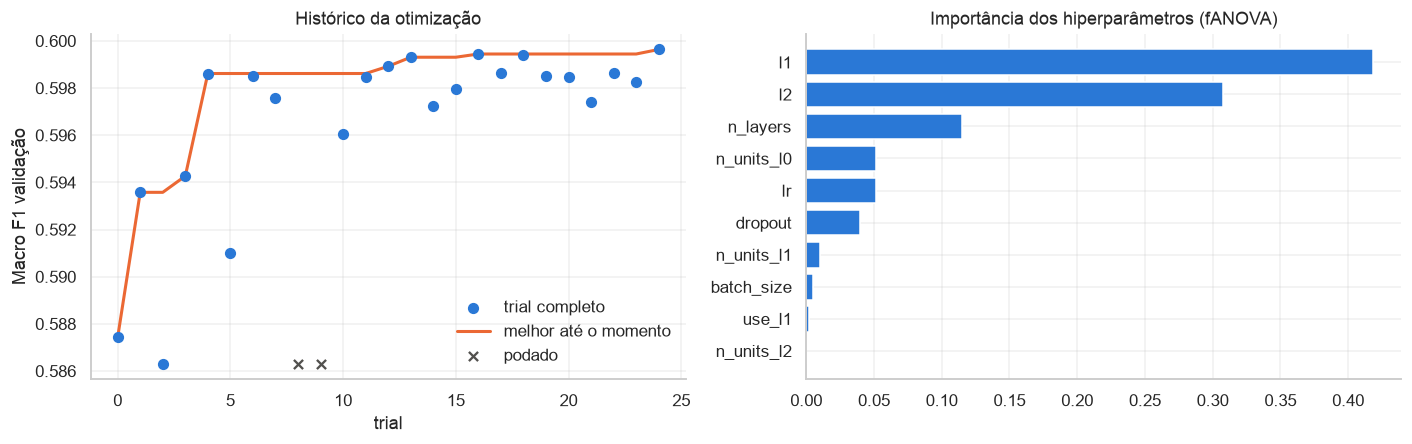

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hist_df = trials_df.sort_values("number"); done = hist_df[hist_df["state"] == "COMPLETE"]; pruned = hist_df[hist_df["state"] == "PRUNED"]
axes[0].scatter(done["number"], done["value"], color="#2a78d6", s=40, label="trial completo", zorder=3)
axes[0].plot(done["number"], done["value"].cummax(), color="#eb6834", lw=2, label="melhor até o momento")
axes[0].scatter(pruned["number"], [done["value"].min()] * len(pruned), marker="x", color="#52514e", label="podado", zorder=3)
axes[0].set_xlabel("trial"); axes[0].set_ylabel("Macro F1 validação"); axes[0].set_title("Histórico da otimização"); axes[0].legend(frameon=False)
imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
axes[1].barh(imp.index, imp.values, color="#2a78d6"); axes[1].set_title("Importância dos hiperparâmetros (fANOVA)")
save_fig("10_optuna")

- 25 trials em 6,2 min; 23 completos, 2 podados. Melhor val Macro F1 0,600 (1 camada de 172, dropout 0,24, lr 4,6e-4, L2 1,1e-5, sem L1, lote 512).
- Os 5 melhores ficam entre 0,599 e 0,600 e usam lote 512: o espaço é pouco sensível; L1 aparece em 2 deles sem efeito.
- Gap treino−val na melhor época ≤ 0,016 em todos os trials.

### 4.3 Largura × profundidade (experimento controlado)
- No Optuna a arquitetura muda junto com dropout, `lr` e L2, então o efeito dela fica misturado.
- Aqui só profundidade (1, 2, 3 camadas) e largura (32, 128, 256 neurônios por camada) variam; o resto fica fixo perto do ótimo da busca: dropout 0,2, `lr` 5e-4, L2 1e-5, sem L1, lote 512.
- Mesmo protocolo da busca: subamostra de 300 k, até 15 épocas, paciência 4, Macro F1 na validação completa.

In [48]:
FIXOS = {"dropout": 0.2, "lr": 5e-4, "l2": 1e-5, "l1": 0.0, "batch_size": 512}
wd_rows = []
for depth in [1, 2, 3]:
    for width in [32, 128, 256]:
        _, h, _ = train_model({**FIXOS, "hidden_units": [width] * depth}, max_epochs=15, patience=4, data=(Xtr_sub, ytr_sub, Xva_t, yva_t))
        be = h["best_epoch"]
        wd_rows.append({"camadas": depth, "neurônios/camada": width, "nº parâmetros": h["n_params"], "melhor época": be,
                        "tempo (s)": round(h["train_time_s"], 1), "val Macro F1": max(h["val_f1"]),
                        "treino Macro F1": h["train_f1"][be - 1], "gap F1": h["train_f1"][be - 1] - h["val_f1"][be - 1]})
wd_df = pd.DataFrame(wd_rows)
wd_df.round(4)

,camadas,neurônios/camada,nº parâmetros,melhor época,tempo (s),val Macro F1,treino Macro F1,gap F1
0,1,32,6339,13,7.0,0.5960,0.6007,0.0047
1,1,128,25347,12,14.6,0.5993,0.6088,0.0094
2,1,256,50691,13,20.6,0.5998,0.6158,0.0159
3,2,32,7395,12,7.7,0.5970,0.6034,0.0064
4,2,128,41859,4,11.1,0.5983,0.6049,0.0066
5,2,256,116483,5,21.4,0.5996,0.6105,0.0110
6,3,32,8451,15,9.9,0.5954,0.6048,0.0094
7,3,128,58371,5,15.9,0.5989,0.6090,0.0101
8,3,256,182275,4,26.1,0.5988,0.6097,0.0109


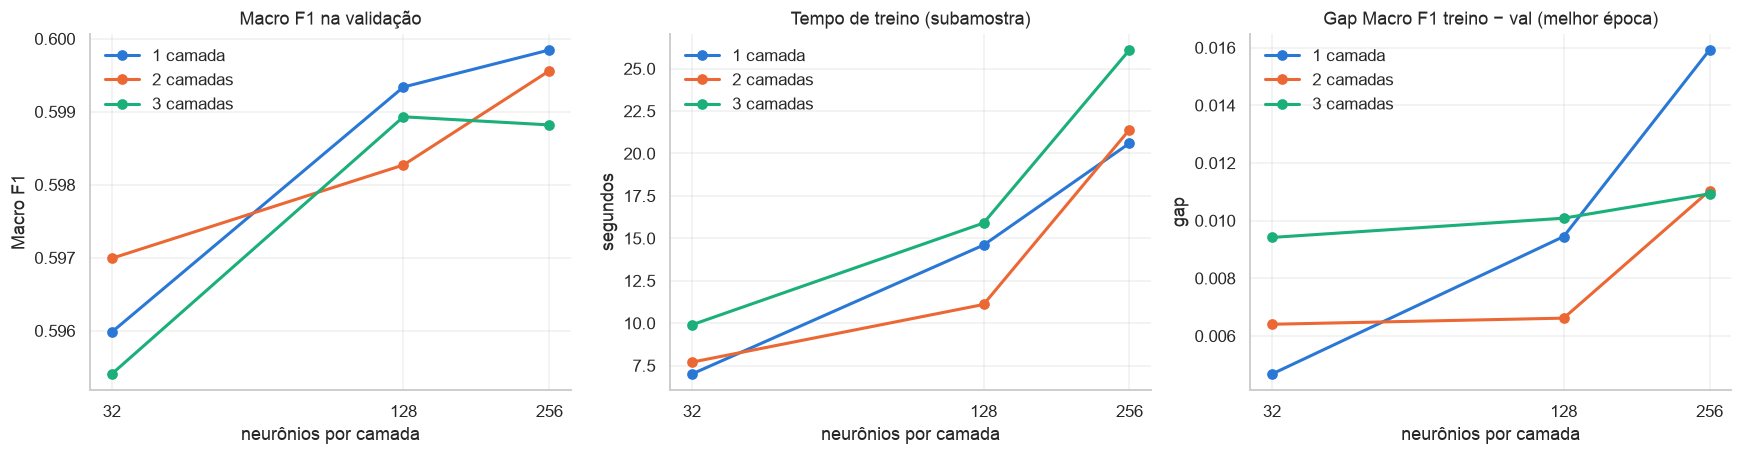

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
cores_d = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
for depth, g in wd_df.groupby("camadas"):
    lbl = f"{depth} camada{'s' if depth > 1 else ''}"
    axes[0].plot(g["neurônios/camada"], g["val Macro F1"], marker="o", lw=2, color=cores_d[depth], label=lbl)
    axes[1].plot(g["neurônios/camada"], g["tempo (s)"], marker="o", lw=2, color=cores_d[depth], label=lbl)
    axes[2].plot(g["neurônios/camada"], g["gap F1"], marker="o", lw=2, color=cores_d[depth], label=lbl)
for ax, t, yl in zip(axes, ["Macro F1 na validação", "Tempo de treino (subamostra)", "Gap Macro F1 treino − val (melhor época)"], ["Macro F1", "segundos", "gap"]):
    ax.set_xscale("log", base=2); ax.set_xticks([32, 128, 256]); ax.set_xticklabels([32, 128, 256])
    ax.set_xlabel("neurônios por camada"); ax.set_title(t); ax.set_ylabel(yl); ax.legend(frameon=False)
save_fig("10b_largura_profundidade_controlado")

In [50]:
best_wd = wd_df.loc[wd_df["val Macro F1"].idxmax()]
print(f"Melhor: {int(best_wd['camadas'])} camada(s) de {int(best_wd['neurônios/camada'])} → val Macro F1 {best_wd['val Macro F1']:.4f}")
print("Amplitude do val Macro F1 entre as 9 redes:", round(wd_df["val Macro F1"].max() - wd_df["val Macro F1"].min(), 4))
wd_df.pivot(index="camadas", columns="neurônios/camada", values="val Macro F1").round(4)

Melhor: 1 camada(s) de 256 → val Macro F1 0.5998
Amplitude do val Macro F1 entre as 9 redes: 0.0044


neurônios/camada,32,128,256
camadas,,,
1,0.5960,0.5993,0.5998
2,0.5970,0.5983,0.5996
3,0.5954,0.5989,0.5988


- Largura pesa mais que profundidade: com 32 neurônios as três profundidades ficam entre 0,595 e 0,597 (gap 0,005–0,009, pouca capacidade); passar para 128 rende +0,001 a +0,004; de 128 para 256, no máximo +0,001.
- Profundidade não ajuda: em 128 e 256 neurônios, 1 camada é igual ou melhor que 2 e 3. Redes de 2–3 camadas largas atingem o melhor já na época 4–5 e depois só aumentam o gap.
- Custo: 3 × 256 tem 182 mil parâmetros e leva 26 s; 1 × 256 tem 51 mil e leva 21 s, com desempenho igual ou melhor.
- Gap cresce com a largura (até 0,016 em 1 × 256). Amplitude total entre as 9 redes: 0,0044 de Macro F1. Confirma o resultado do Optuna (melhor trial com 1 camada de 172).

### 4.4 Finalistas
- 3 melhores trials completos com arquiteturas distintas.

In [51]:
completed = sorted([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE], key=lambda t: t.value, reverse=True)
top3, seen = [], set()
for t in completed:
    arch = tuple(t.user_attrs["hidden_units"])
    if arch not in seen:
        seen.add(arch); top3.append(t)
    if len(top3) == 3: break

def params_from_trial(t):
    p = t.params
    return {"hidden_units": t.user_attrs["hidden_units"], "dropout": p["dropout"], "lr": p["lr"], "l2": p["l2"],
            "l1": p.get("l1", 0.0) if p["use_l1"] else 0.0, "batch_size": p["batch_size"]}

pd.DataFrame([{"modelo": f"M{i+1}", "trial": t.number, "val Macro F1 (busca)": round(t.value, 4),
               "arquitetura": " -> ".join(map(str, t.user_attrs["hidden_units"])) + " -> 3",
               **{k: (round(v, 6) if isinstance(v, float) else v) for k, v in params_from_trial(t).items() if k != "hidden_units"}}
              for i, t in enumerate(top3)])

,modelo,trial,val Macro F1 (busca),arquitetura,dropout,lr,l2,l1,batch_size
0,M1,24,0.5996,172 -> 3,0.238119,0.000460,0.000011,0.0,512
1,M2,16,0.5994,215 -> 25 -> 3,0.315509,0.000722,0.000012,0.0,512
2,M3,18,0.5994,219 -> 17 -> 3,0.396506,0.000934,0.000008,0.0,512


## 5. Avaliação no teste
### 5.1 Métricas e matriz de confusão
- Cada finalista é re-treinado do zero no treino completo e avaliado uma única vez no teste.

In [52]:
final_models, final_histories, test_preds, rows = {}, {}, {}, []
for i, t in enumerate(top3):
    name, params = f"M{i+1}", params_from_trial(t)
    model, hist, criterion = train_model(params, max_epochs=30, patience=5)      # treino COMPLETO
    t_inf = time.time(); _, _, _, logits = evaluate(model, Xte_t, yte_t, criterion); inference_ms = (time.time() - t_inf) * 1000
    y_pred = logits.argmax(1).numpy()
    final_models[name], final_histories[name], test_preds[name] = model, hist, y_pred
    rows.append({"modelo": name, "arquitetura": " -> ".join(map(str, params["hidden_units"])) + " -> 3", "nº parâmetros": hist["n_params"],
                 "épocas": len(hist["train_loss"]), "melhor época": hist["best_epoch"], "tempo treino (s)": round(hist["train_time_s"], 1),
                 "inferência teste (ms)": round(inference_ms, 1), "Acurácia": accuracy_score(y_test, y_pred),
                 "Precisão (macro)": precision_score(y_test, y_pred, average="macro"), "Revocação (macro)": recall_score(y_test, y_pred, average="macro"),
                 "Macro F1": f1_score(y_test, y_pred, average="macro"), "val Macro F1": max(hist["val_f1"])})
    torch.save(model.state_dict(), ARTIFACTS_DIR / f"mlp_{name}.pt")
    print(f"{name} pronto em {hist['train_time_s']:.0f} s")
results_df = pd.DataFrame(rows).set_index("modelo")
results_df.round(4)

M1 pronto em 119 s
M2 pronto em 580 s
M3 pronto em 261 s


,arquitetura,nº parâmetros,épocas,melhor época,tempo treino (s),inferência teste (ms),Acurácia,Precisão (macro),Revocação (macro),Macro F1,val Macro F1
modelo,,,,,,,,,,,
M1,172 -> 3,34059,22,17,119.4,125.8,0.7029,0.6020,0.6140,0.6065,0.6046
M2,215 -> 25 -> 3,47403,13,8,579.9,97.7,0.7029,0.6034,0.6142,0.6065,0.6041
M3,219 -> 17 -> 3,46499,8,3,261.0,97.5,0.7023,0.6051,0.6077,0.6041,0.6017


In [53]:
for name, y_pred in test_preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

=== M1 ===
                     precision    recall  f1-score   support

        Sem Vítimas      0.720     0.783     0.750    156012
Com Vítimas Feridas      0.726     0.656     0.689    161392
 Com Vítimas Fatais      0.360     0.403     0.380     16394

           accuracy                          0.703    333798
          macro avg      0.602     0.614     0.607    333798
       weighted avg      0.705     0.703     0.703    333798

=== M2 ===
                     precision    recall  f1-score   support

        Sem Vítimas      0.713     0.800     0.754    156012
Com Vítimas Feridas      0.734     0.639     0.684    161392
 Com Vítimas Fatais      0.363     0.403     0.382     16394

           accuracy                          0.703    333798
          macro avg      0.603     0.614     0.607    333798
       weighted avg      0.706     0.703     0.702    333798

=== M3 ===
                     precision    recall  f1-score   support

        Sem Vítimas      0.709     0.805     

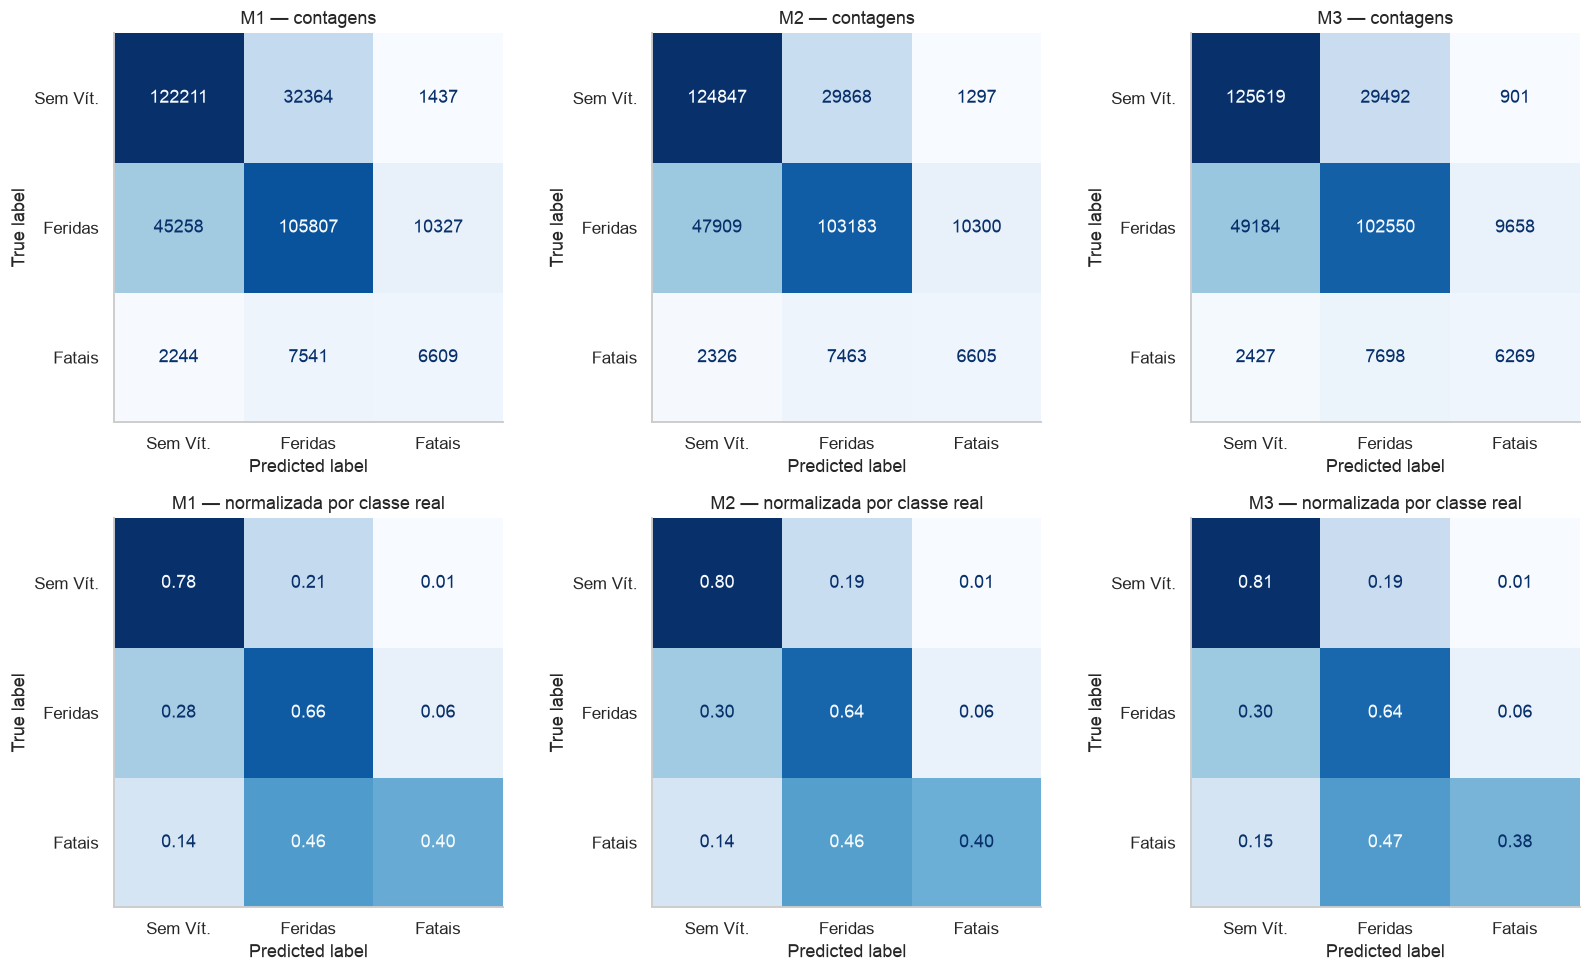

In [54]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, (name, y_pred) in enumerate(test_preds.items()):
    for r, norm in enumerate([None, "true"]):
        ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize=norm), display_labels=["Sem Vít.", "Feridas", "Fatais"]).plot(
            ax=axes[r, j], cmap="Blues", colorbar=False, values_format=".0f" if norm is None else ".2f")
        axes[r, j].set_title(f"{name} — {'contagens' if norm is None else 'normalizada por classe real'}"); axes[r, j].grid(False)
save_fig("11_matrizes_confusao")

- Acurácia 70,2–70,3%; Macro F1 0,604–0,607; F1 por classe 0,75 / 0,68 / 0,38 (sem vítimas / feridas / fatais).
- Classe fatal: revocação 38–40%, precisão 36–37%; erro dominante fatal→ferido.
- M1 (1 camada, 34 k parâmetros) empata com M2/M3 (2 camadas, 46–47 k): capacidade extra não rende.

### 5.2 Curvas (perda, acurácia, Macro F1) e efeito da regularização

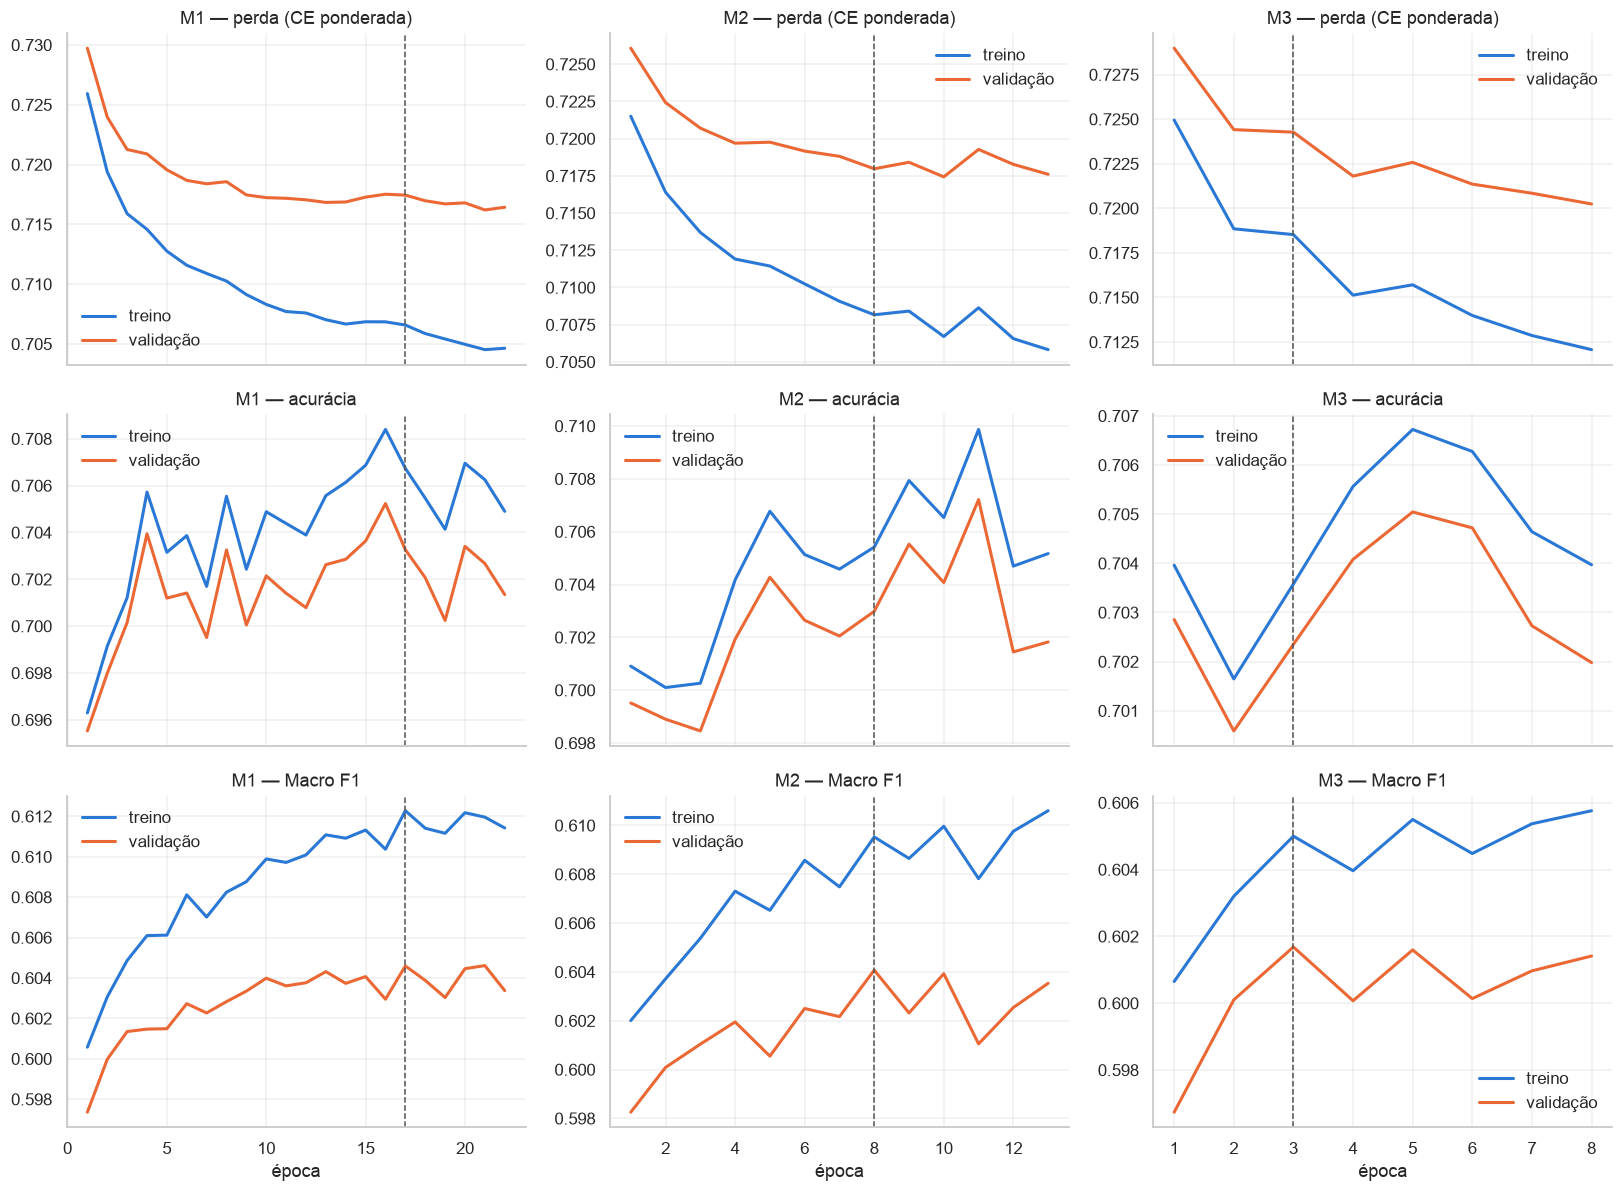

In [55]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex="col")
for j, (name, hist) in enumerate(final_histories.items()):
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    for r, (key, label) in enumerate([("loss", "perda (CE ponderada)"), ("acc", "acurácia"), ("f1", "Macro F1")]):
        axes[r, j].plot(ep, hist[f"train_{key}"], color="#2a78d6", lw=2, label="treino")
        axes[r, j].plot(ep, hist[f"val_{key}"], color="#eb6834", lw=2, label="validação")
        axes[r, j].axvline(hist["best_epoch"], color="#52514e", ls="--", lw=1)
        axes[r, j].set_title(f"{name} — {label}"); axes[r, j].legend(frameon=False)
    axes[2, j].set_xlabel("época")
save_fig("12_curvas_treino_validacao")

In [56]:
pd.DataFrame({name: {"loss treino (última)": h["train_loss"][-1], "loss val (última)": h["val_loss"][-1],
                     "acc treino (melhor época)": h["train_acc"][h["best_epoch"]-1], "acc val (melhor época)": h["val_acc"][h["best_epoch"]-1],
                     "F1 treino (melhor época)": h["train_f1"][h["best_epoch"]-1], "F1 val (melhor época)": h["val_f1"][h["best_epoch"]-1],
                     "épocas treinadas": len(h["train_loss"])} for name, h in final_histories.items()}).T.round(4)

,loss treino (última),loss val (última),acc treino (melhor época),acc val (melhor época),F1 treino (melhor época),F1 val (melhor época),épocas treinadas
M1,0.7046,0.7164,0.7067,0.7033,0.6123,0.6046,22.0
M2,0.7058,0.7176,0.7054,0.7030,0.6095,0.6041,13.0
M3,0.7121,0.7202,0.7036,0.7024,0.6050,0.6017,8.0


#### Regularização técnica por técnica
- Mesma arquitetura (a de mais parâmetros entre os finalistas), mesma `lr` e lote, subamostra de 300 k, **25 épocas sem parada antecipada**.
- Cada técnica entra isolada, com intensidade moderada: só dropout (taxa do Optuna), só L2 (1e-4), só L1 (1e-5), só BatchNorm.
- Referências: sem regularização, a combinação do Optuna e uma regularização forte (dropout 0,5 + L2 1e-2).

In [57]:
base_name = max(final_models, key=lambda n: final_histories[n]["n_params"])
base = params_from_trial(top3[int(base_name[1:]) - 1])
nenhuma = {**base, "dropout": 0.0, "l1": 0.0, "l2": 0.0}
variants = {"sem regularização": nenhuma,
            f"só dropout ({base['dropout']:.2f})": {**nenhuma, "dropout": base["dropout"]},
            "só L2 (1e-4)": {**nenhuma, "l2": 1e-4},
            "só L1 (1e-5)": {**nenhuma, "l1": 1e-5},
            "só BatchNorm": {**nenhuma, "batch_norm": True},
            "regularização do Optuna": base,
            "regularização forte": {**base, "dropout": 0.5, "l1": 0.0, "l2": 1e-2}}
abl_hist = {v: train_model(p, max_epochs=25, patience=25, data=(Xtr_sub, ytr_sub, Xva_t, yva_t))[1] for v, p in variants.items()}
print("arquitetura:", base_name, results_df.loc[base_name, "arquitetura"])

arquitetura: M2 215 -> 25 -> 3


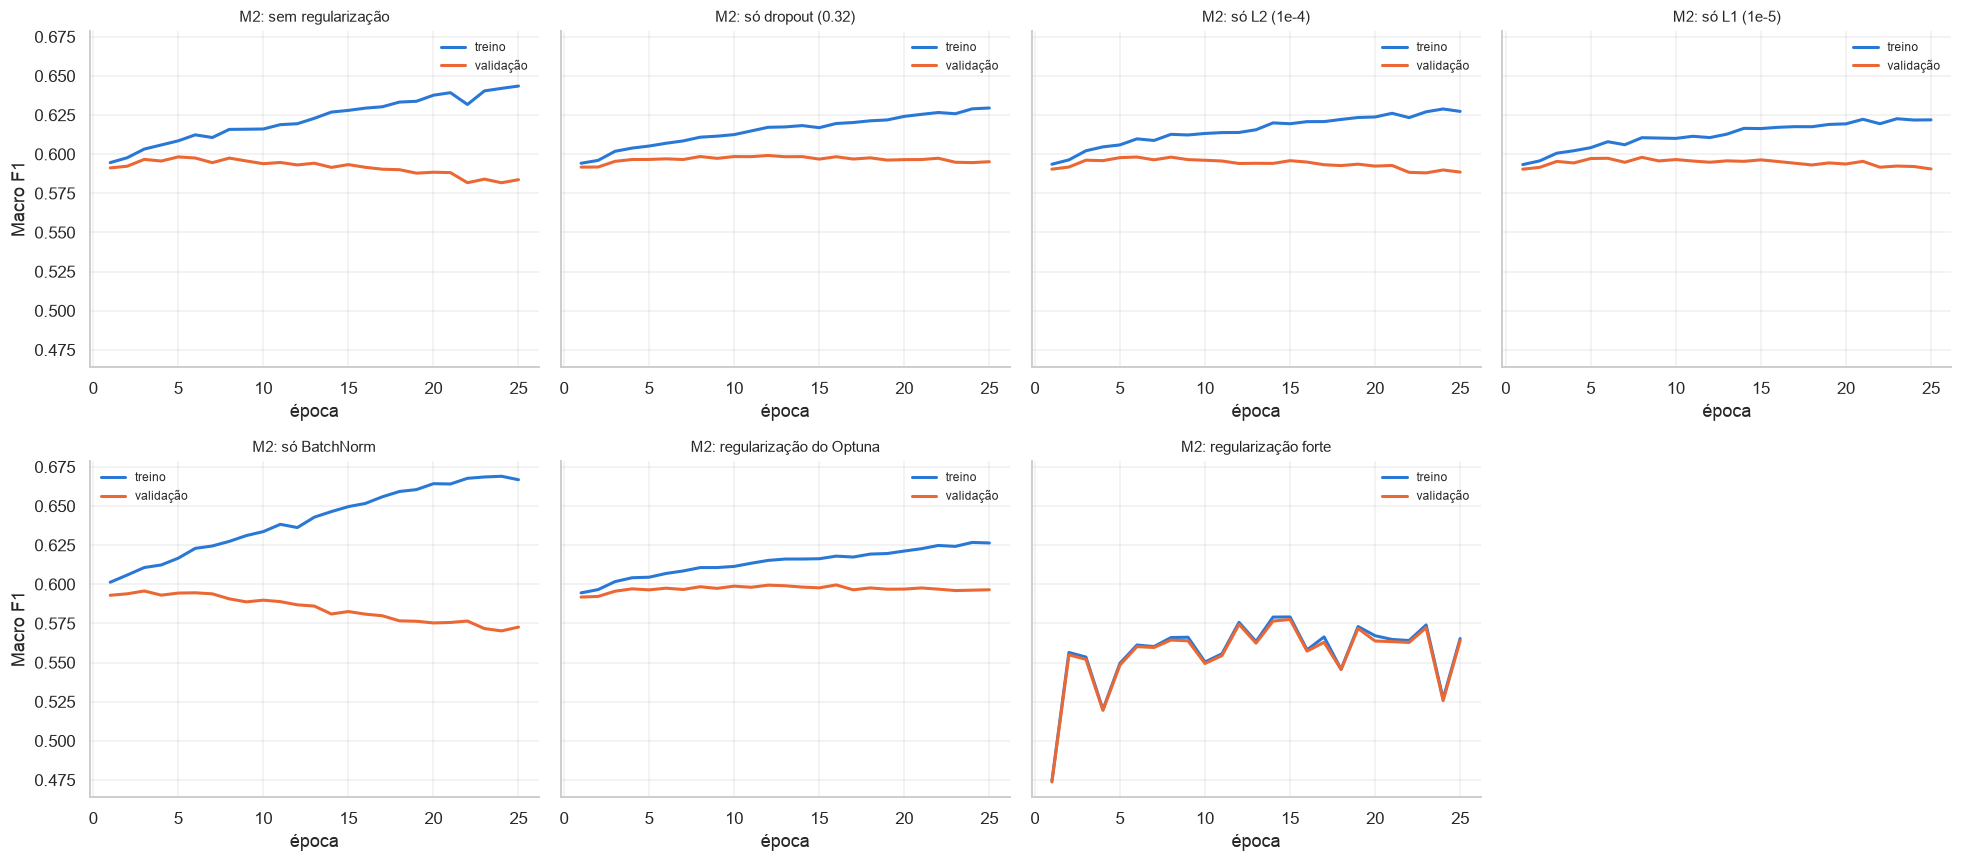

In [58]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, (vname, h) in zip(axes.ravel(), abl_hist.items()):
    ep = np.arange(1, len(h["train_f1"]) + 1)
    ax.plot(ep, h["train_f1"], color="#2a78d6", lw=2, label="treino"); ax.plot(ep, h["val_f1"], color="#eb6834", lw=2, label="validação")
    ax.set_title(f"{base_name}: {vname}", fontsize=10); ax.set_xlabel("época"); ax.legend(frameon=False, fontsize=8)
axes[0, 0].set_ylabel("Macro F1"); axes[1, 0].set_ylabel("Macro F1"); axes[1, 3].axis("off")
save_fig("13_ablacao_regularizacao")

In [59]:
reg_df = pd.DataFrame({v: {"F1 treino (última época)": h["train_f1"][-1], "F1 val (última época)": h["val_f1"][-1],
                           "F1 val (melhor)": max(h["val_f1"]), "época do melhor val": int(np.argmax(h["val_f1"])) + 1,
                           "gap treino − val (última)": h["train_f1"][-1] - h["val_f1"][-1], "tempo (s)": round(h["train_time_s"], 1)}
                       for v, h in abl_hist.items()}).T
reg_df.round(4)

,F1 treino (última época),F1 val (última época),F1 val (melhor),época do melhor val,gap treino − val (última),tempo (s)
sem regularização,0.6435,0.5837,0.5983,5.0,0.0598,124.4
só dropout (0.32),0.6295,0.5952,0.5992,12.0,0.0343,221.0
só L2 (1e-4),0.6273,0.5886,0.5982,6.0,0.0388,105.6
só L1 (1e-5),0.6219,0.5906,0.5980,8.0,0.0314,246.4
só BatchNorm,0.6668,0.5726,0.5957,3.0,0.0941,336.9
regularização do Optuna,0.6264,0.5965,0.5996,16.0,0.0299,158.7
regularização forte,0.5653,0.5640,0.5775,15.0,0.0013,85.8


#### Parada antecipada: efeito da paciência
- As curvas acima vão até a 25ª época sem parada. Simulamos sobre elas a regra usada no treino (melhora mínima 1e-4 no Macro F1 de validação) com paciências de 1 a 10.
- Para cada paciência: época em que o treino pararia, Macro F1 de validação restaurado e diferença para o melhor das 25 épocas.

In [60]:
def simula_parada(val_f1, patience, min_delta=1e-4):
    best, best_ep, bad = -1.0, 0, 0
    for ep, v in enumerate(val_f1, 1):
        if v > best + min_delta: best, best_ep, bad = v, ep, 0
        else:
            bad += 1
            if bad >= patience: return ep, best_ep, best
    return len(val_f1), best_ep, best

pat_rows = []
for v in ["sem regularização", f"só dropout ({base['dropout']:.2f})", "regularização do Optuna"]:
    vf = abl_hist[v]["val_f1"]
    for pat in [1, 2, 3, 4, 5, 8, 10]:
        stop, be, bv = simula_parada(vf, pat)
        pat_rows.append({"configuração": v, "paciência": pat, "pararia na época": stop, "época restaurada": be,
                         "val Macro F1 restaurado": bv, "perda vs. melhor de 25 épocas": max(vf) - bv})
pat_df = pd.DataFrame(pat_rows)
pat_df.pivot(index="paciência", columns="configuração", values="val Macro F1 restaurado").round(4)

configuração,regularização do Optuna,sem regularização,só dropout (0.32)
paciência,,,
1,0.5971,0.5967,0.5917
2,0.5994,0.5983,0.5985
3,0.5994,0.5983,0.5985
4,0.5996,0.5983,0.5992
5,0.5996,0.5983,0.5992
8,0.5996,0.5983,0.5992
10,0.5996,0.5983,0.5992


In [61]:
pat_df.pivot(index="paciência", columns="configuração", values="pararia na época")

configuração,regularização do Optuna,sem regularização,só dropout (0.32)
paciência,,,
1,5,4,2
2,14,7,10
3,15,8,11
4,20,9,16
5,21,10,17
8,24,13,20
10,25,15,22


- Perda de treino cai em todas as épocas; a perda de validação também cai, cada vez mais devagar. O Macro F1 de validação para de melhorar e oscila: melhor época 17 (M1), 8 (M2) e 3 (M3). A parada é disparada por essa oscilação, não por subida da perda de validação.
- Gap treino−validação de 0,003 a 0,008 em Macro F1 na melhor época: sobreajuste leve; acurácia de validação varia 0,3–0,5 p.p. entre épocas.
- M3 parou na época 8 com a perda de validação ainda caindo: paciência 5 sobre uma métrica ruidosa pode ter parado cedo.
- Regularização técnica por técnica (25 épocas, sem parada antecipada):
  - Sem regularização: gap 0,060 e melhor val 0,598 já na época 5, depois a validação cai → **sobreajuste**.
  - Só dropout (0,32): gap 0,034, melhor val 0,599 na época 12. Técnica isolada mais eficaz.
  - Só L2 (1e-4): gap 0,039, val 0,598. Só L1 (1e-5): gap 0,031, val 0,598. Reduzem o gap, mas sem ganho na validação.
  - Só BatchNorm: gap 0,094 (maior que sem regularização), melhor val 0,596 na época 3. Acelera o ajuste ao treino e piora o sobreajuste; com entradas binárias e rede rasa, não regulariza. Por isso não foi usado.
  - Combinação do Optuna: gap 0,030 e o melhor val (0,600). Forte (dropout 0,5 + L2 1e-2): gap 0,001 e val 0,578 → **subajuste**.
- Paciência: com paciência 1 o treino para cedo demais (perde 0,002–0,008); com 4 ou 5, as três configurações recuperam o melhor valor das 25 épocas; acima de 5 só gasta épocas. Justifica a paciência 4 (busca) e 5 (treino final).

### 5.3 Baselines, teto do contexto e ablação por grupo de entradas
- Baselines: classe majoritária, sorteio proporcional, regressão logística (mesmas 12 entradas e pesos, `C` escolhido na validação).
- Teto do contexto: tabela de frequências das 4 entradas de contexto (classe mais frequente por combinação no treino).
- Ablação: arquitetura de M1 treinada com contexto → +quando/onde → +relato.

In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from scipy.sparse import csr_matrix

def metrics_row(name, y_pred):
    return {"modelo": name, "Acurácia": accuracy_score(y_test, y_pred), "Precisão (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
            "Revocação (macro)": recall_score(y_test, y_pred, average="macro"), "Macro F1": f1_score(y_test, y_pred, average="macro")}

rows = []
for s in ["most_frequent", "stratified"]:
    t0 = time.time(); dummy = DummyClassifier(strategy=s, random_state=SEED).fit(X_train_enc, y_train); fit_s = time.time() - t0
    rows.append({**metrics_row(f"Baseline: {s}", dummy.predict(X_test_enc)), "tempo treino (s)": round(fit_s, 1)})
pd.DataFrame(rows).set_index("modelo").round(4)

,Acurácia,Precisão (macro),Revocação (macro),Macro F1,tempo treino (s)
modelo,,,,,
Baseline: most_frequent,0.4835,0.1612,0.3333,0.2173,0.0
Baseline: stratified,0.4551,0.3335,0.3335,0.3335,0.0


In [63]:
# hiperparâmetro da regressão logística: C (inverso da regularização L2), escolhido pelo Macro F1 na validação, ajuste na subamostra
cw = {i: w for i, w in enumerate(class_weights)}
Xsub_csr, Xva_csr = csr_matrix(Xtr_sub.numpy()), csr_matrix(X_val_enc)
lr_search = []
for C in [0.01, 0.1, 1.0, 10.0]:
    t0 = time.time(); m = LogisticRegression(C=C, max_iter=500, class_weight=cw).fit(Xsub_csr, ytr_sub.numpy())
    lr_search.append({"C": C, "val Macro F1": f1_score(y_val, m.predict(Xva_csr), average="macro"), "tempo (s)": round(time.time() - t0, 1)})
lr_search_df = pd.DataFrame(lr_search)
best_C = lr_search_df.loc[lr_search_df["val Macro F1"].idxmax(), "C"]
lr_search_df.round(4)

,C,val Macro F1,tempo (s)
0,0.01,0.5836,3.5
1,0.10,0.5848,5.2
2,1.00,0.5851,106.4
3,10.00,0.5851,5.4


In [64]:
t0 = time.time(); lr_clf = LogisticRegression(C=best_C, max_iter=500, class_weight=cw).fit(csr_matrix(X_train_enc), y_train); lr_fit_s = time.time() - t0
rows.append({**metrics_row(f"Regressão logística (12 entradas, C={best_C:g})", lr_clf.predict(csr_matrix(X_test_enc))), "tempo treino (s)": round(lr_fit_s, 1)})
rows[-1]

{'modelo': 'Regressão logística (12 entradas, C=1)',
 'Acurácia': 0.6848453256160911,
 'Precisão (macro)': 0.586651715817205,
 'Revocação (macro)': 0.5979481377695085,
 'Macro F1': 0.5883325641831563,
 'tempo treino (s)': 258.9}

In [65]:
combo_train = X_train[CONTEXTO].astype(str).agg(" | ".join, axis=1)
combo_test = X_test[CONTEXTO].astype(str).agg(" | ".join, axis=1)
t0 = time.time()
table = pd.crosstab(combo_train, y_train)
lookup = pd.Series(table.values.argmax(1), index=table.index)                       # classe mais frequente por combinação
lookup_s = time.time() - t0
pred_lookup = combo_test.map(lookup).fillna(int(np.argmax(np.bincount(y_train)))).astype(int).values
print(f"Combinações distintas das 4 entradas de contexto no treino: {len(table)}")
rows.append({**metrics_row("Só contexto: tabela de frequências (teto para essas entradas)", pred_lookup), "tempo treino (s)": round(lookup_s, 1)})
rows[-1]

Combinações distintas das 4 entradas de contexto no treino: 414


{'modelo': 'Só contexto: tabela de frequências (teto para essas entradas)',
 'Acurácia': 0.5285322260768489,
 'Precisão (macro)': 0.3523692996291597,
 'Revocação (macro)': 0.37059076502045807,
 'Macro F1': 0.36124963704572055,
 'tempo treino (s)': 0.2}

In [66]:
for name in test_preds:
    rows.append({**metrics_row(f"MLP {name} ({results_df.loc[name, 'arquitetura']})", test_preds[name]), "tempo treino (s)": results_df.loc[name, "tempo treino (s)"]})
comparison = pd.DataFrame(rows).set_index("modelo")
comparison.round(4)

,Acurácia,Precisão (macro),Revocação (macro),Macro F1,tempo treino (s)
modelo,,,,,
Baseline: most_frequent,0.4835,0.1612,0.3333,0.2173,0.0
Baseline: stratified,0.4551,0.3335,0.3335,0.3335,0.0
"Regressão logística (12 entradas, C=1)",0.6848,0.5867,0.5979,0.5883,258.9
Só contexto: tabela de frequências (teto para essas entradas),0.5285,0.3524,0.3706,0.3612,0.2
MLP M1 (172 -> 3),0.7029,0.6020,0.6140,0.6065,119.4
MLP M2 (215 -> 25 -> 3),0.7029,0.6034,0.6142,0.6065,579.9
MLP M3 (219 -> 17 -> 3),0.7023,0.6051,0.6077,0.6041,261.0


In [67]:
grupos = {"Contexto da via (4)": CONTEXTO, "+ quando/onde (8)": CONTEXTO + QUANDO_ONDE, "+ relato do solicitante (12)": FEATURES}
params_abl = params_from_trial(top3[0]); abl_rows = []
for gname, cols in grupos.items():
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200, sparse_output=False, dtype=np.float32).fit(X_train[cols])
    to_t = lambda df_: torch.from_numpy(enc.transform(df_[cols]))
    Xtr_v, Xva_v, Xte_v = to_t(X_train), to_t(X_val), to_t(X_test)
    model_v, hist_v, crit_v = train_model(params_abl, max_epochs=25, patience=5, data=(Xtr_v, ytr_t, Xva_v, yva_t))
    y_pred_v = evaluate(model_v, Xte_v, yte_t, crit_v)[3].argmax(1).numpy()
    abl_rows.append({**metrics_row(gname, y_pred_v), "colunas one-hot": Xtr_v.shape[1], "val Macro F1": max(hist_v["val_f1"]),
                     "Revocação fatais": recall_score(y_test, y_pred_v, average=None)[2], "Precisão fatais": precision_score(y_test, y_pred_v, average=None, zero_division=0)[2]})
    print(f"{gname}: pronto")
abl_df = pd.DataFrame(abl_rows).set_index("modelo")
abl_df.round(4)

Contexto da via (4): pronto
+ quando/onde (8): pronto
+ relato do solicitante (12): pronto


,Acurácia,Precisão (macro),Revocação (macro),Macro F1,colunas one-hot,val Macro F1,Revocação fatais,Precisão fatais
modelo,,,,,,,,
Contexto da via (4),0.5287,0.3524,0.3707,0.3613,21,0.3619,0.0000,0.0000
+ quando/onde (8),0.5574,0.4437,0.4139,0.4188,159,0.4169,0.0761,0.2026
+ relato do solicitante (12),0.7029,0.6020,0.6140,0.6065,194,0.6046,0.4031,0.3597


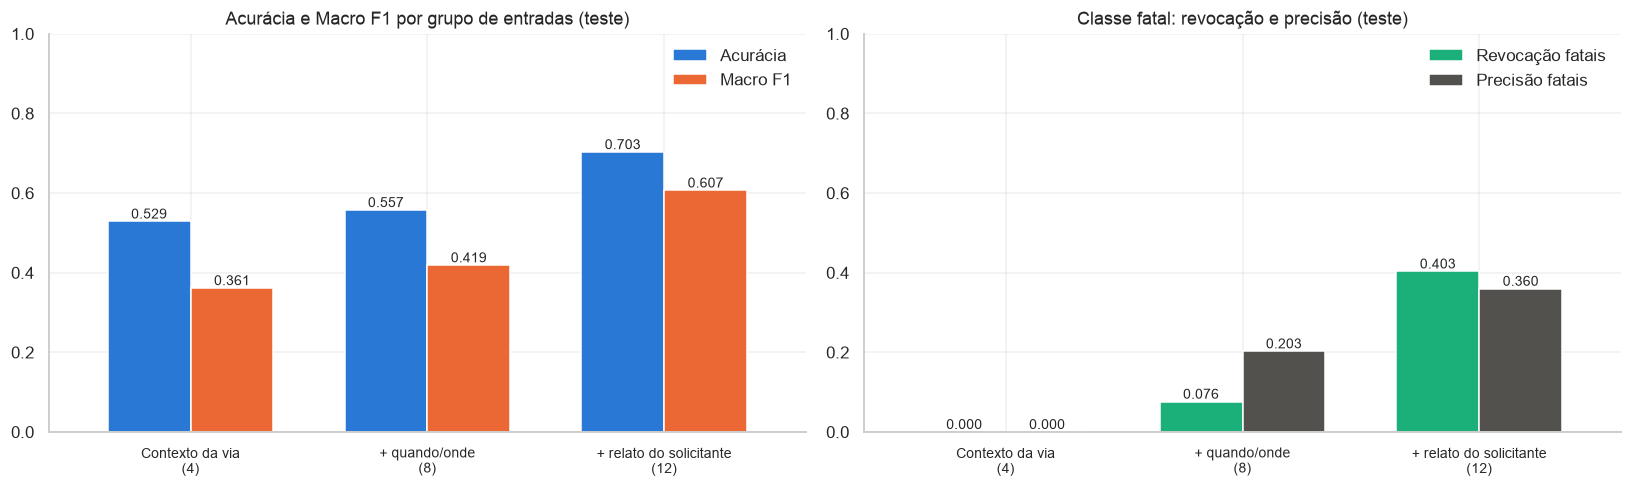

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, cols, colors, title in [(axes[0], ["Acurácia", "Macro F1"], ["#2a78d6", "#eb6834"], "Acurácia e Macro F1 por grupo de entradas (teste)"),
                                (axes[1], ["Revocação fatais", "Precisão fatais"], ["#1baf7a", "#52514e"], "Classe fatal: revocação e precisão (teste)")]:
    abl_df[cols].plot(kind="bar", ax=ax, color=colors, width=0.7, rot=0)
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=9)
    ax.set_ylim(0, 1); ax.set_title(title); ax.legend(frameon=False); ax.set_xlabel("")
    ax.set_xticklabels([t.get_text().replace(" (", "\n(") for t in ax.get_xticklabels()], fontsize=9)
save_fig("14_ablacao_grupos_entradas")

- Só contexto: tabela de frequências 52,9% / 0,361; MLP com as mesmas 4 entradas 52,9% / 0,361 e 0 fatais previstos. Teto dessas entradas.
- +quando/onde: 55,7% / 0,419 (revocação fatal 8%). +relato do solicitante: **70,3% / 0,607**, revocação fatal 40%.
- Regressão logística: `C` em {0,01; 0,1; 1; 10} na validação → 0,584–0,585, praticamente insensível; escolhido C = 1. No teste: 68,5% / 0,588.
- MLP M1: 70,3% / 0,607. +1,8 p.p.: a arquitetura pesa pouco; as entradas pesam muito.

### 5.4 Limitações

- Custo: treino final de 2 a 10 min por modelo em CPU (1,56 M linhas); inferência de 334 k linhas em < 0,2 s. Busca em subamostra de 300 k transferiu (val 0,600 → 0,605 no treino completo).
- Dois regimes de registro sem `ano`; `nao informada` (causa "outras" pré-2017) ainda marca o período antigo.
- Sinônimos de `tipo_acidente` unificados à mão; categorias raras (< 200) → "infrequente".
- Classe fatal: 40% de revocação com 36% de precisão; limiar de alerta deve vir do custo do erro; nunca usar para negar socorro.
- Divisão única (val 0,605 vs. teste 0,604–0,607); sem validação cruzada pelo custo com 2,2 M linhas.
- Pesos de classe com expoente fixo (0,5); outro valor trocaria acurácia por revocação dos fatais de outra forma.

## 6. Conclusão

- Contexto da via sozinho: 53% (teto). Com o relato do solicitante: 70% / Macro F1 0,61 / revocação fatal 40%.
- Ganho vem de `tipo_acidente`, `macro_causa`, `pessoas`, `veiculos`; MLP supera a regressão logística por 1,8 p.p.
- Arquitetura: no experimento controlado, largura ajuda até ~128 neurônios e profundidade não ajuda; 1 camada basta (M1, 34 k parâmetros).
- Regularização: dropout é a técnica isolada mais eficaz; L2/L1 reduzem o gap sem ganho na validação; BatchNorm piora o sobreajuste; regularização forte subajusta. Paciência 4–5 recupera o melhor de 25 épocas.
- `ano` e causa bruta excluídos para não aprender o procedimento de registro da PRF em vez da gravidade.
- Próximos passos: saída ordinal, calibração e limiar por custo; coletar velocidade, pessoas presas e tipo de veículo.

## Artefatos

In [69]:
with open(ARTIFACTS_DIR / "onehot_encoder.pkl", "wb") as f: pickle.dump(encoder, f)
results_df.round(4).to_csv(ARTIFACTS_DIR / "resultados_teste.csv")
comparison.round(4).to_csv(ARTIFACTS_DIR / "comparacao_baselines.csv")
abl_df.round(4).to_csv(ARTIFACTS_DIR / "ablacao_grupos_entradas.csv")
trials_df.round(5).to_csv(ARTIFACTS_DIR / "optuna_trials.csv", index=False)
wd_df.round(4).to_csv(ARTIFACTS_DIR / "largura_profundidade.csv", index=False)
reg_df.round(4).to_csv(ARTIFACTS_DIR / "ablacao_regularizacao.csv")
pat_df.round(4).to_csv(ARTIFACTS_DIR / "paciencia_parada_antecipada.csv", index=False)
lr_search_df.round(4).to_csv(ARTIFACTS_DIR / "busca_regressao_logistica.csv", index=False)
json.dump({"classes": CLASSES, "features": FEATURES, "class_weights": class_weights.tolist(), "top3": [params_from_trial(t) for t in top3]},
          open(ARTIFACTS_DIR / "config_final.json", "w"), indent=2, ensure_ascii=False)
sorted(p.name for p in ARTIFACTS_DIR.iterdir())

['ablacao_grupos_entradas.csv',
 'ablacao_regularizacao.csv',
 'busca_regressao_logistica.csv',
 'comparacao_baselines.csv',
 'config_final.json',
 'figuras',
 'largura_profundidade.csv',
 'mlp_M1.pt',
 'mlp_M2.pt',
 'mlp_M3.pt',
 'onehot_encoder.pkl',
 'optuna_trials.csv',
 'paciencia_parada_antecipada.csv',
 'resultados_teste.csv']

In [70]:
sorted(p.name for p in FIG_DIR.iterdir())        # figuras salvas em PNG

['01_alvo.png',
 '02_hora_dia_semana.png',
 '03_contexto_por_regime.png',
 '04_relato_por_regime.png',
 '05_uf.png',
 '06_composicao_contexto.png',
 '07_composicao_relato.png',
 '08_heatmaps_contexto.png',
 '09_amplitude_fatais.png',
 '10_optuna.png',
 '10b_largura_profundidade_controlado.png',
 '11_matrizes_confusao.png',
 '12_curvas_treino_validacao.png',
 '13_ablacao_regularizacao.png',
 '14_ablacao_grupos_entradas.png']

In [71]:
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
results_df.round(4)                               # modelos finais no teste

,arquitetura,nº parâmetros,épocas,melhor época,tempo treino (s),inferência teste (ms),Acurácia,Precisão (macro),Revocação (macro),Macro F1,val Macro F1
modelo,,,,,,,,,,,
M1,172 -> 3,34059,22,17,119.4,125.8,0.7029,0.6020,0.6140,0.6065,0.6046
M2,215 -> 25 -> 3,47403,13,8,579.9,97.7,0.7029,0.6034,0.6142,0.6065,0.6041
M3,219 -> 17 -> 3,46499,8,3,261.0,97.5,0.7023,0.6051,0.6077,0.6041,0.6017


In [72]:
comparison.round(4)                               # comparação com baselines

,Acurácia,Precisão (macro),Revocação (macro),Macro F1,tempo treino (s)
modelo,,,,,
Baseline: most_frequent,0.4835,0.1612,0.3333,0.2173,0.0
Baseline: stratified,0.4551,0.3335,0.3335,0.3335,0.0
"Regressão logística (12 entradas, C=1)",0.6848,0.5867,0.5979,0.5883,258.9
Só contexto: tabela de frequências (teto para essas entradas),0.5285,0.3524,0.3706,0.3612,0.2
MLP M1 (172 -> 3),0.7029,0.6020,0.6140,0.6065,119.4
MLP M2 (215 -> 25 -> 3),0.7029,0.6034,0.6142,0.6065,579.9
MLP M3 (219 -> 17 -> 3),0.7023,0.6051,0.6077,0.6041,261.0


In [73]:
abl_df.round(4)                                   # ablação por grupo de entradas

,Acurácia,Precisão (macro),Revocação (macro),Macro F1,colunas one-hot,val Macro F1,Revocação fatais,Precisão fatais
modelo,,,,,,,,
Contexto da via (4),0.5287,0.3524,0.3707,0.3613,21,0.3619,0.0000,0.0000
+ quando/onde (8),0.5574,0.4437,0.4139,0.4188,159,0.4169,0.0761,0.2026
+ relato do solicitante (12),0.7029,0.6020,0.6140,0.6065,194,0.6046,0.4031,0.3597


In [74]:
wd_df.round(4)                                    # largura × profundidade (controlado)

,camadas,neurônios/camada,nº parâmetros,melhor época,tempo (s),val Macro F1,treino Macro F1,gap F1
0,1,32,6339,13,7.0,0.5960,0.6007,0.0047
1,1,128,25347,12,14.6,0.5993,0.6088,0.0094
2,1,256,50691,13,20.6,0.5998,0.6158,0.0159
3,2,32,7395,12,7.7,0.5970,0.6034,0.0064
4,2,128,41859,4,11.1,0.5983,0.6049,0.0066
5,2,256,116483,5,21.4,0.5996,0.6105,0.0110
6,3,32,8451,15,9.9,0.5954,0.6048,0.0094
7,3,128,58371,5,15.9,0.5989,0.6090,0.0101
8,3,256,182275,4,26.1,0.5988,0.6097,0.0109


In [75]:
reg_df.round(4)                                   # regularização técnica por técnica

,F1 treino (última época),F1 val (última época),F1 val (melhor),época do melhor val,gap treino − val (última),tempo (s)
sem regularização,0.6435,0.5837,0.5983,5.0,0.0598,124.4
só dropout (0.32),0.6295,0.5952,0.5992,12.0,0.0343,221.0
só L2 (1e-4),0.6273,0.5886,0.5982,6.0,0.0388,105.6
só L1 (1e-5),0.6219,0.5906,0.5980,8.0,0.0314,246.4
só BatchNorm,0.6668,0.5726,0.5957,3.0,0.0941,336.9
regularização do Optuna,0.6264,0.5965,0.5996,16.0,0.0299,158.7
regularização forte,0.5653,0.5640,0.5775,15.0,0.0013,85.8


In [76]:
trials_df.drop(columns=["datetime_start", "datetime_complete", "duration"], errors="ignore").round(4)   # todos os trials do Optuna

,number,value,state,batch_size,dropout,l1,l2,lr,n_layers,n_units_l0,n_units_l1,n_units_l2,use_l1,best_epoch,gap_f1,hidden_units,n_params,train_time_s
0,24,0.5996,COMPLETE,512,0.2381,NaN,0.0000,0.0005,1,172,NaN,NaN,False,10.0,0.0080,[172],34059.0,16.4
1,16,0.5994,COMPLETE,512,0.3155,0.0000,0.0000,0.0007,2,215,25.0,NaN,True,12.0,0.0158,"[215, 25]",47403.0,24.2
2,18,0.5994,COMPLETE,512,0.3965,0.0000,0.0000,0.0009,2,219,17.0,NaN,True,7.0,0.0078,"[219, 17]",46499.0,17.6
3,13,0.5993,COMPLETE,512,0.1696,NaN,0.0001,0.0005,2,228,19.0,NaN,False,14.0,0.0142,"[228, 19]",48871.0,22.0
4,12,0.5989,COMPLETE,512,0.1384,NaN,0.0000,0.0003,2,253,19.0,NaN,False,14.0,0.0123,"[253, 19]",54221.0,22.6
5,17,0.5986,COMPLETE,512,0.1479,NaN,0.0000,0.0007,2,212,47.0,NaN,False,5.0,0.0111,"[212, 47]",51495.0,13.6
6,22,0.5986,COMPLETE,512,0.4043,0.0000,0.0000,0.0009,3,154,23.0,198.0,True,9.0,0.0114,"[154, 23, 198]",38944.0,23.6
7,4,0.5986,COMPLETE,512,0.0226,NaN,0.0000,0.0004,3,206,20.0,27.0,False,6.0,0.0078,"[206, 20, 27]",44961.0,14.1
8,19,0.5985,COMPLETE,512,0.3079,0.0000,0.0001,0.0009,2,245,16.0,NaN,True,9.0,0.0090,"[245, 16]",51762.0,22.4
9,6,0.5985,COMPLETE,512,0.0318,0.0000,0.0000,0.0003,2,89,39.0,NaN,True,12.0,0.0079,"[89, 39]",20985.0,13.8
